# Análise Comparativa Final — Competição PICME Cats vs Dogs (IMPA Tech)

Este notebook consolida as análises finais dos **quatro modelos principais** desenvolvidos na competição de classificação binária de imagens (**Gatos vs. Cachorros**), integrando:
1. A documentação e auditoria técnica da pasta [`Competicao/`](Competicao/README.md) ([`EVOLUCAO_TREINAMENTOS.md`](Competicao/EVOLUCAO_TREINAMENTOS.md) e [`BANCOS_DE_DADOS.md`](Competicao/BANCOS_DE_DADOS.md));
2. A metodologia de análise exploratória e avaliação de [`Mateus/Analysis/results_final.ipynb`](Mateus/Analysis/results_final.ipynb);
3. O relatório comparativo e os dados de avaliação externa unificada no banco **Pets (78 imagens: 45 gatos e 33 cães)** em [`dataset/`](dataset/) e [`Competicao/coisas para apresentacao/Resumo publico Pets/`](Competicao/coisas%20para%20apresentacao/Resumo%20publico%20Pets/RELATORIO_PERFORMANCE.md);
4. A avaliação rigorosa de **cada modelo em sua respectiva configuração nativa de treino**, contrastando o pipeline autêntico de preservação de proporção (`Resize(384) + CenterCrop(384)`) com o redimensionamento forçado preliminar (`Resize((384, 384))`).

---

### Participantes e Modelos Finais Avaliados

| Participante | Modelo Principal | Origem dos Pesos | Resolução | Seleção do Checkpoint | Validação Interna | Banco Externo `Pets` (78 fotos) |
| :--- | :--- | :--- | :---: | :--- | :---: | :---: |
| **Theo** | `ResTheo34 Aug8` | Pré-treinado (ImageNet ResNet-34 sem `layer4`) → Repetição → Aug8 | `224×224` | Maior `val_acc` (Época 29/30) | **98,32%** | **84,62%** (66/78 · 1º) |
| **Mateus (Bandeira)** | `CNN V4 Final` | Do zero (`V4` 30 ép.) + Fine-Tuning parcial (`V4 Final` 10 ép.) | `384×384` | Menor `val_loss` (Época 10/10 FT) | **94,76%** *(pico 94,80%)* | **82,05%** (64/78 · 2º)* |
| **Dulce** | `CNN224 v2` | Do zero (5 blocos `Conv5×5` + cabeça densa) | `224×224` | Maior `val_acc` (Época 112/120) | **96,90%** *(teste 96,43%)* | **75,64%** (59/78 · 3º) |
| **Lisandra** | `AlexNetBinary` | Do zero (5 blocos `Conv` + `BatchNorm` + cabeça `4096→4096→1`) | `224×224` | Menor `val_loss` (Época 5/10) | **90,16%** *(pico 91,08% ép. 8)* | **61,54%** (48/78 · 4º) |

> **Nota Metodológica Importante:**
> * **Validações internas distintas:** Cada participante definiu seu próprio split, tratamento de duplicatas/corrompidos, resolução e normalização durante o treinamento. Portanto, as métricas de validação interna refletem o desempenho dentro do protocolo de cada autor.
> * **Teste externo comum (`Pets` — 78 fotos em `dataset/`):** Os quatro checkpoints fechados foram submetidos às 78 fotos (**45 gatos** e **33 cachorros**) em modo `eval()`, com limiar padrão $P(\text{Cão}) \ge 0{,}5$, avaliando **cada modelo em sua própria transformação nativa de treinamento**.
> * **(*) Avaliação Autêntica vs. Redimensionamento Direto no Modelo do Mateus:** Quando avaliado com o pipeline autêntico do autor (`Resize(384)` proporcional pelo menor lado + `CenterCrop(384)` central, conforme publicado em `Mateus/Analysis/results_final.ipynb`), o modelo `CNN V4 Final` atinge **82,05% (64/78 acertos)**, ficando a apenas **2 fotos do Theo** e registrando a **menor queda de generalização de toda a competição (-12,71 p.p.)**. Quando submetido ao redimensionamento anisotrópico direto `Resize((384, 384))` adotado no script preliminar do Theo (`avaliar_pets.py`), a acurácia cai para **78,21% (61/78 acertos)** devido à distorção morfológica nas cabeças e orelhas dos felinos.


## 1. Configuração do Ambiente, Paleta Oficial e Carregamento de Dados

In [1]:
from pathlib import Path
import csv
import json
import xml.etree.ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Image as IPyImage, display

try:
    import pandas as pd
except ImportError:
    pd = None

# Diretório raiz do repositório unificado
ROOT = Path(".").resolve()
if not (ROOT / "Competicao").exists():
    ROOT = Path("/home/al.mateus.torres/Documentos/PICME-Cats-vs-Dogs")

RESUMO_PETS_DIR = ROOT / "Competicao/coisas para apresentacao/Resumo publico Pets"
APRES_DIR = ROOT / "Competicao/coisas para apresentacao"

# Paleta oficial adotada nos relatórios e apresentações da competição
PALETA = {
    "Theo": "#286b78",
    "Bandeira": "#4367a6",
    "Mateus": "#4367a6",
    "Dulce": "#b96238",
    "Lisandra": "#8b5290",
}

plt.rcParams.update({
    "figure.facecolor": "#fcfbf8",
    "axes.facecolor": "#ffffff",
    "axes.edgecolor": "#dce1e3",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.color": "#657384",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})


def exibir_tabela(linhas, colunas=None, titulo=None):
    """Exibe uma lista de dicionários como DataFrame (se pandas disponível) ou tabela HTML formatada."""
    if titulo:
        display(HTML(f"<h4 style='margin:10px 0 4px 0;color:#202c39'>{titulo}</h4>"))
    if pd is not None:
        df = pd.DataFrame(linhas)
        if colunas:
            df = df[colunas]
        display(df)
        return df
    cols = colunas or list(linhas[0].keys())
    th = "".join(f"<th style='padding:6px 10px;border-bottom:2px solid #202c39;text-align:left;background:#f4f1ea'>{c}</th>" for c in cols)
    trs = []
    for r in linhas:
        tds = "".join(f"<td style='padding:6px 10px;border-bottom:1px solid #dce1e3'>{r.get(c, '')}</td>" for c in cols)
        trs.append(f"<tr>{tds}</tr>")
    html_table = f"<table style='border-collapse:collapse;font-size:13px;color:#202c39'><thead><tr>{th}</tr></thead><tbody>{''.join(trs)}</tbody></table>"
    display(HTML(html_table))
    return linhas


print(f"Diretório raiz configurado: {ROOT}")
print(f"Arquivos de avaliação Pets encontrados: {sorted(p.name for p in RESUMO_PETS_DIR.iterdir())}")

/home/al.mateus.torres/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-kw4v56vl because there was an issue with the default path (/home/al.mateus.torres/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Diretório raiz configurado: /home/al.mateus.torres/Documentos/PICME-Cats-vs-Dogs
Arquivos de avaliação Pets encontrados: ['README.md', 'RELATORIO_PERFORMANCE.md', 'amostra_augmentation_theo.png', 'concordancia.svg', 'matrizes_confusao.svg', 'ranking.csv', 'ranking.pdf', 'ranking.png', 'ranking.svg', 'validacao_vs_pets.csv', 'validacao_vs_pets.pdf', 'validacao_vs_pets.png', 'validacao_vs_pets.svg']


## 2. Comparação de Arquiteturas, Hiperparâmetros e Bancos de Dados

A tabela a seguir sintetiza as especificações técnicas auditadas nos códigos, configurações e relatórios de cada participante ([`metodos_treinamento_pets.py`](Competicao/metodos_treinamento_pets.py) e [`BANCOS_DE_DADOS.md`](Competicao/BANCOS_DE_DADOS.md)).

In [2]:
comparativo_metodos = [
    {
        "Critério": "Modelo Principal",
        "Theo — Aug8": "ResTheo34 (ResNet-34 sem layer4, canais 64/128/256 + GAP + Linear 256→1)",
        "Bandeira (Mateus) — V4 Final": "CNN V4 Final (5 blocos Conv3×3+BN+ReLU+Pool, 32→512 + GAP + Linear 512→1)",
        "Dulce — CNN224 v2": "CNN224 v2 (5 blocos Conv5×5+ReLU+Pool+Drop20%, 32→128 + FC 3200→1024→32→2)",
        "Lisandra — AlexNetBinary": "AlexNetBinary (5 Conv 11/5/3/3/3 + BN + ReLU + Pool + FC 9216→4096→4096→1)",
    },
    {
        "Critério": "Origem dos Pesos",
        "Theo — Aug8": "Pré-treinado ImageNet → Repetição (ép. 33) → Aug8",
        "Bandeira (Mateus) — V4 Final": "Treinado do zero (V4 base, 30 ép.) → Fine-tuning parcial (10 ép.)",
        "Dulce — CNN224 v2": "Treinado do zero (seed 18)",
        "Lisandra — AlexNetBinary": "Treinado do zero (sem seed fixa declarada)",
    },
    {
        "Critério": "Resolução e Pré-processamento",
        "Theo — Aug8": "224×224 RGB | Eval: menor lado 256 + CenterCrop 224 | Normalize ImageNet",
        "Bandeira (Mateus) — V4 Final": "384×384 RGB | Resize 384×384 | Normalize próprio (norm_stats_3.0.json)",
        "Dulce — CNN224 v2": "224×224 RGB | Crop central proporcional em box PIL | Escala [0, 1] sem Normalize",
        "Lisandra — AlexNetBinary": "224×224 RGB | Resize direto 224×224 | Normalize ImageNet",
    },
    {
        "Critério": "Divisão do Banco (Treino / Val / Teste)",
        "Theo — Aug8": "19.998 treino orig. (159.984 virtuais 8×) / 5.000 val (80/20 balanceado)",
        "Bandeira (Mateus) — V4 Final": "20.000 treino / 5.000 val (80/20 estratificado, seed 42)",
        "Dulce — CNN224 v2": "17.934 orig. (21.520 c/ cópias fixas) / 3.165 val / 3.723 teste (deduplicado, >=94px)",
        "Lisandra — AlexNetBinary": "19.998 treino / 2.500 val / 2.500 teste (80/10/10 aleatório)",
    },
    {
        "Critério": "Data Augmentation",
        "Theo — Aug8": "8 variantes virtuais/época: ruído gaussiano+2% brancos, 8 quadrados pretos, stretch 2× H/V + combinações",
        "Bandeira (Mateus) — V4 Final": "V4: RRC384(0.8-1.0), Flip, Rot ±15°, Jitter 0.2 | Final: RRC384(0.9-1.0), Flip, Rot ±5°, Jitter 0.05",
        "Dulce — CNN224 v2": "Fixo (+10% rot 15°, +10% ruído) + Online nos lotes (flip, zoom 0.7-1, translação, rot ±15°, brilho/contraste)",
        "Lisandra — AlexNetBinary": "Sem data augmentation declarado",
    },
    {
        "Critério": "Otimizador e Learning Rate (Fase Final)",
        "Theo — Aug8": "AdamW (wd=0,01) | LR diferencial: 1e-5 (base), 5e-5 (layer3), 1e-4 (fc)",
        "Bandeira (Mateus) — V4 Final": "AdamW (wd=1e-4) | V4: LR 1e-3 → Final: LR 1e-5 (blocos 1–3 congelados)",
        "Dulce — CNN224 v2": "Adam (wd=0) | LR fixo 3e-4",
        "Lisandra — AlexNetBinary": "Adam (wd=0) | LR fixo 1e-4",
    },
    {
        "Critério": "Scheduler e Épocas",
        "Theo — Aug8": "CosineAnnealingLR (T_max=30, eta_min=1e-7) | 30 épocas no Aug8 (AMP)",
        "Bandeira (Mateus) — V4 Final": "CosineAnnealingLR (T_max=30 na V4; T_max=10 até 1e-7 na Final) | 30 + 10 épocas (AMP)",
        "Dulce — CNN224 v2": "Sem scheduler no treino final | 120 épocas (batch 32)",
        "Lisandra — AlexNetBinary": "Sem scheduler | Early Stopping (paciência 5) parou na época 10 de 40 (batch 50)",
    },
    {
        "Critério": "Regularização e Função de Perda",
        "Theo — Aug8": "BatchNorm (ResNet) + Dropout 10% antes de fc | BCEWithLogitsLoss",
        "Bandeira (Mateus) — V4 Final": "BatchNorm após cada Conv + Dropout 50% na cabeça | BCEWithLogitsLoss",
        "Dulce — CNN224 v2": "Dropout 20% após cada MaxPool (5 blocos), sem BatchNorm | NLLLoss (LogSoftmax)",
        "Lisandra — AlexNetBinary": "BatchNorm após cada Conv + 2× Dropout 50% na cabeça | BCEWithLogitsLoss",
    },
    {
        "Critério": "Critério e Época do Checkpoint",
        "Theo — Aug8": "Maior acurácia de validação → Época 29 (98,32%, BCE 0,0533)",
        "Bandeira (Mateus) — V4 Final": "Menor perda de validação → Época 10 Final / 40 total (94,76%, BCE 0,1336)",
        "Dulce — CNN224 v2": "Maior acurácia de validação → Época 112 (96,90%, perda 0,0940)",
        "Lisandra — AlexNetBinary": "Menor perda de validação → Época 5 (90,16%, BCE 0,2237; pico acc 91,08% na ép. 8)",
    },
]

_ = exibir_tabela(
    comparativo_metodos,
    titulo="Tabela 1 — Síntese de Arquitetura, Dados e Hiperparâmetros dos 4 Modelos Principais",
)

Critério,Theo — Aug8,Bandeira (Mateus) — V4 Final,Dulce — CNN224 v2,Lisandra — AlexNetBinary
Modelo Principal,"ResTheo34 (ResNet-34 sem layer4, canais 64/128/256 + GAP + Linear 256→1)","CNN V4 Final (5 blocos Conv3×3+BN+ReLU+Pool, 32→512 + GAP + Linear 512→1)","CNN224 v2 (5 blocos Conv5×5+ReLU+Pool+Drop20%, 32→128 + FC 3200→1024→32→2)",AlexNetBinary (5 Conv 11/5/3/3/3 + BN + ReLU + Pool + FC 9216→4096→4096→1)
Origem dos Pesos,Pré-treinado ImageNet → Repetição (ép. 33) → Aug8,"Treinado do zero (V4 base, 30 ép.) → Fine-tuning parcial (10 ép.)",Treinado do zero (seed 18),Treinado do zero (sem seed fixa declarada)
Resolução e Pré-processamento,224×224 RGB | Eval: menor lado 256 + CenterCrop 224 | Normalize ImageNet,384×384 RGB | Resize 384×384 | Normalize próprio (norm_stats_3.0.json),"224×224 RGB | Crop central proporcional em box PIL | Escala [0, 1] sem Normalize",224×224 RGB | Resize direto 224×224 | Normalize ImageNet
Divisão do Banco (Treino / Val / Teste),19.998 treino orig. (159.984 virtuais 8×) / 5.000 val (80/20 balanceado),"20.000 treino / 5.000 val (80/20 estratificado, seed 42)","17.934 orig. (21.520 c/ cópias fixas) / 3.165 val / 3.723 teste (deduplicado, >=94px)",19.998 treino / 2.500 val / 2.500 teste (80/10/10 aleatório)
Data Augmentation,"8 variantes virtuais/época: ruído gaussiano+2% brancos, 8 quadrados pretos, stretch 2× H/V + combinações","V4: RRC384(0.8-1.0), Flip, Rot ±15°, Jitter 0.2 | Final: RRC384(0.9-1.0), Flip, Rot ±5°, Jitter 0.05","Fixo (+10% rot 15°, +10% ruído) + Online nos lotes (flip, zoom 0.7-1, translação, rot ±15°, brilho/contraste)",Sem data augmentation declarado
Otimizador e Learning Rate (Fase Final),"AdamW (wd=0,01) | LR diferencial: 1e-5 (base), 5e-5 (layer3), 1e-4 (fc)",AdamW (wd=1e-4) | V4: LR 1e-3 → Final: LR 1e-5 (blocos 1–3 congelados),Adam (wd=0) | LR fixo 3e-4,Adam (wd=0) | LR fixo 1e-4
Scheduler e Épocas,"CosineAnnealingLR (T_max=30, eta_min=1e-7) | 30 épocas no Aug8 (AMP)",CosineAnnealingLR (T_max=30 na V4; T_max=10 até 1e-7 na Final) | 30 + 10 épocas (AMP),Sem scheduler no treino final | 120 épocas (batch 32),Sem scheduler | Early Stopping (paciência 5) parou na época 10 de 40 (batch 50)
Regularização e Função de Perda,BatchNorm (ResNet) + Dropout 10% antes de fc | BCEWithLogitsLoss,BatchNorm após cada Conv + Dropout 50% na cabeça | BCEWithLogitsLoss,"Dropout 20% após cada MaxPool (5 blocos), sem BatchNorm | NLLLoss (LogSoftmax)",BatchNorm após cada Conv + 2× Dropout 50% na cabeça | BCEWithLogitsLoss
Critério e Época do Checkpoint,"Maior acurácia de validação → Época 29 (98,32%, BCE 0,0533)","Menor perda de validação → Época 10 Final / 40 total (94,76%, BCE 0,1336)","Maior acurácia de validação → Época 112 (96,90%, perda 0,0940)","Menor perda de validação → Época 5 (90,16%, BCE 0,2237; pico acc 91,08% na ép. 8)"


### 2.1. Ilustração das 8 Variantes de Data Augmentation do Theo (`Aug8`)

Um diferencial importante do modelo `ResTheo34 Aug8` foi a combinação de *transfer learning* com um esquema intensivo de perturbações geométricas e fotométricas (ruído gaussiano + pixels brancos, oclusão por 8 quadrados pretos na região central e esticamentos 2× horizontal/vertical seguidos de recorte central). Abaixo carregamos a amostra gerada pelo próprio `DatasetManifesto` em [`Competicao/coisas para apresentacao/Resumo publico Pets/amostra_augmentation_theo.png`](Competicao/coisas%20para%20apresentacao/Resumo%20publico%20Pets/amostra_augmentation_theo.png):

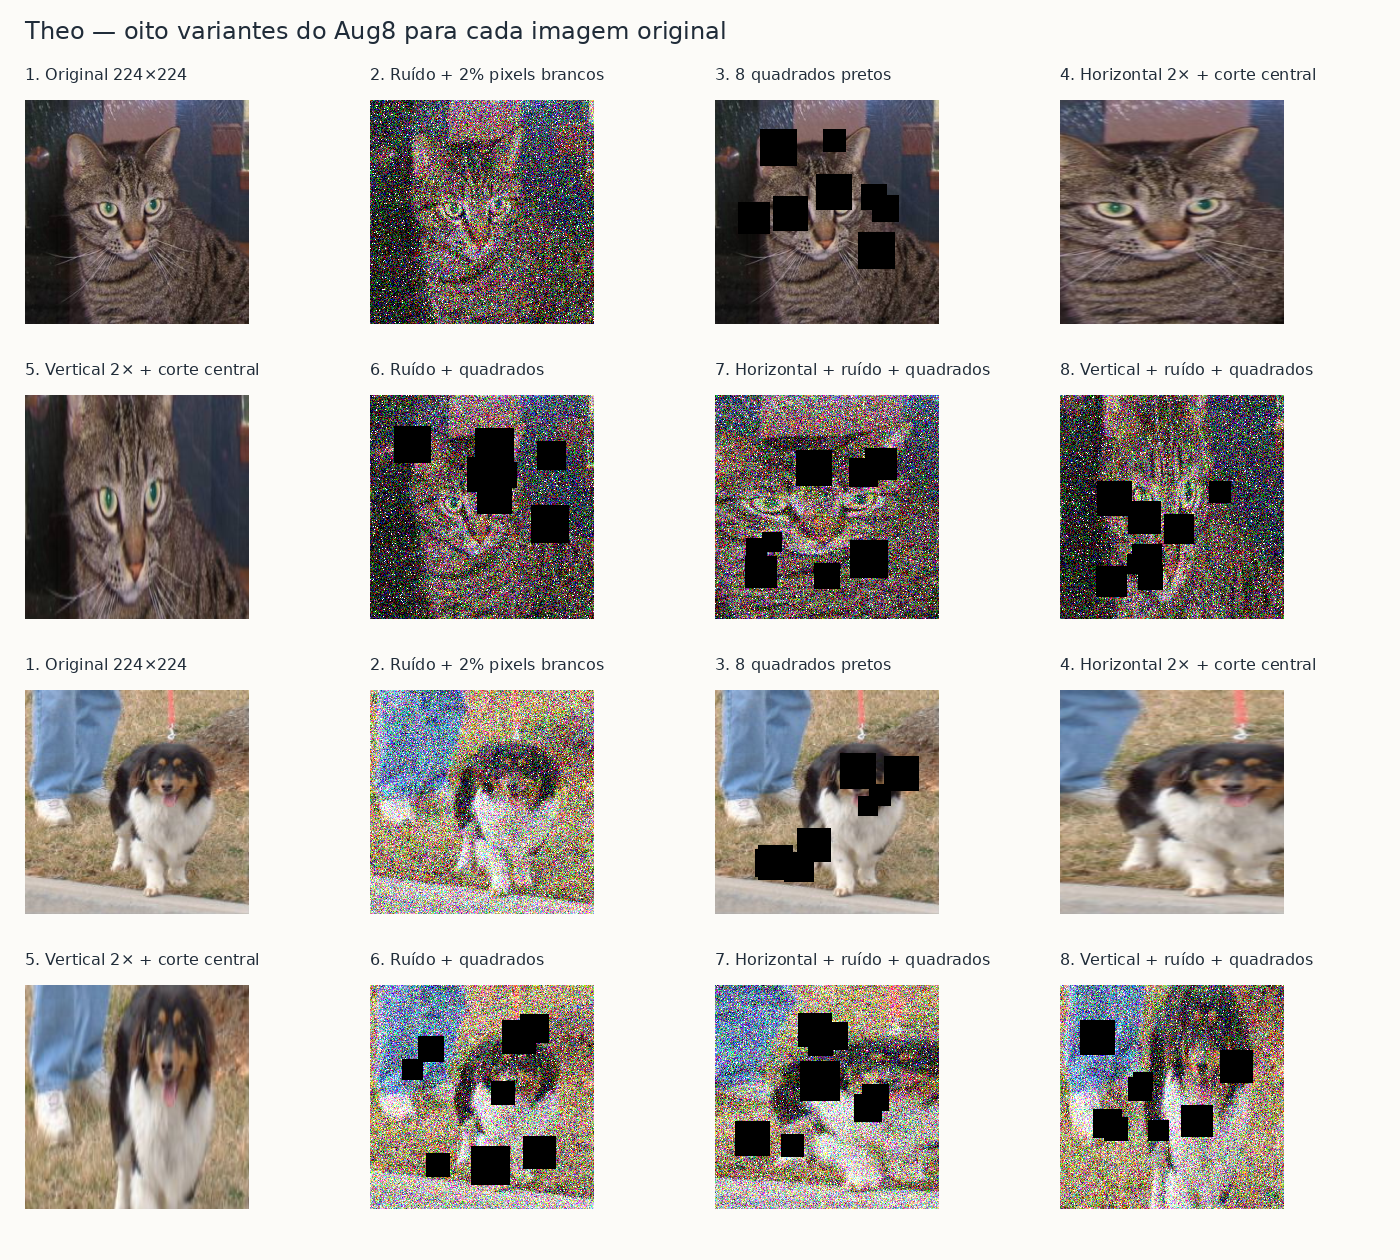

In [3]:
amostra_aug_path = RESUMO_PETS_DIR / "amostra_augmentation_theo.png"
if amostra_aug_path.exists():
    display(IPyImage(filename=str(amostra_aug_path), width=850))
else:
    print(f"Arquivo não encontrado: {amostra_aug_path}")

### 2.2. Diagramas das 4 Arquiteturas ("Formato Livro") e Complexidade de Parâmetros

Um aspecto estrutural decisivo entre os 4 modelos está na transição entre o **extrator convolucional (*backbone*)** e a **cabeça classificadora**:
* **Theo (`ResTheo34 Aug8`)** e **Bandeira / Mateus (`CNN V4 Final`)** utilizam **Global Average Pooling (`GAP`)**, reduzindo cada canal a um único escalar antes da camada linear final (`256→1` no Theo com apenas **257 parâmetros** na cabeça; `512→1` no Bandeira com apenas **513 parâmetros** na cabeça).
* **Dulce (`CNN224 v2`)** e **Lisandra (`AlexNetBinary`)** utilizam **`Flatten` seguido de camadas densas (`FC`)** (`3200→1024→32→2` na Dulce, concentrando **79,2%** dos parâmetros na cabeça; `9216→4096→4096→1` na Lisandra, concentrando **93,6%** dos **58,29 milhões** de parâmetros na cabeça).

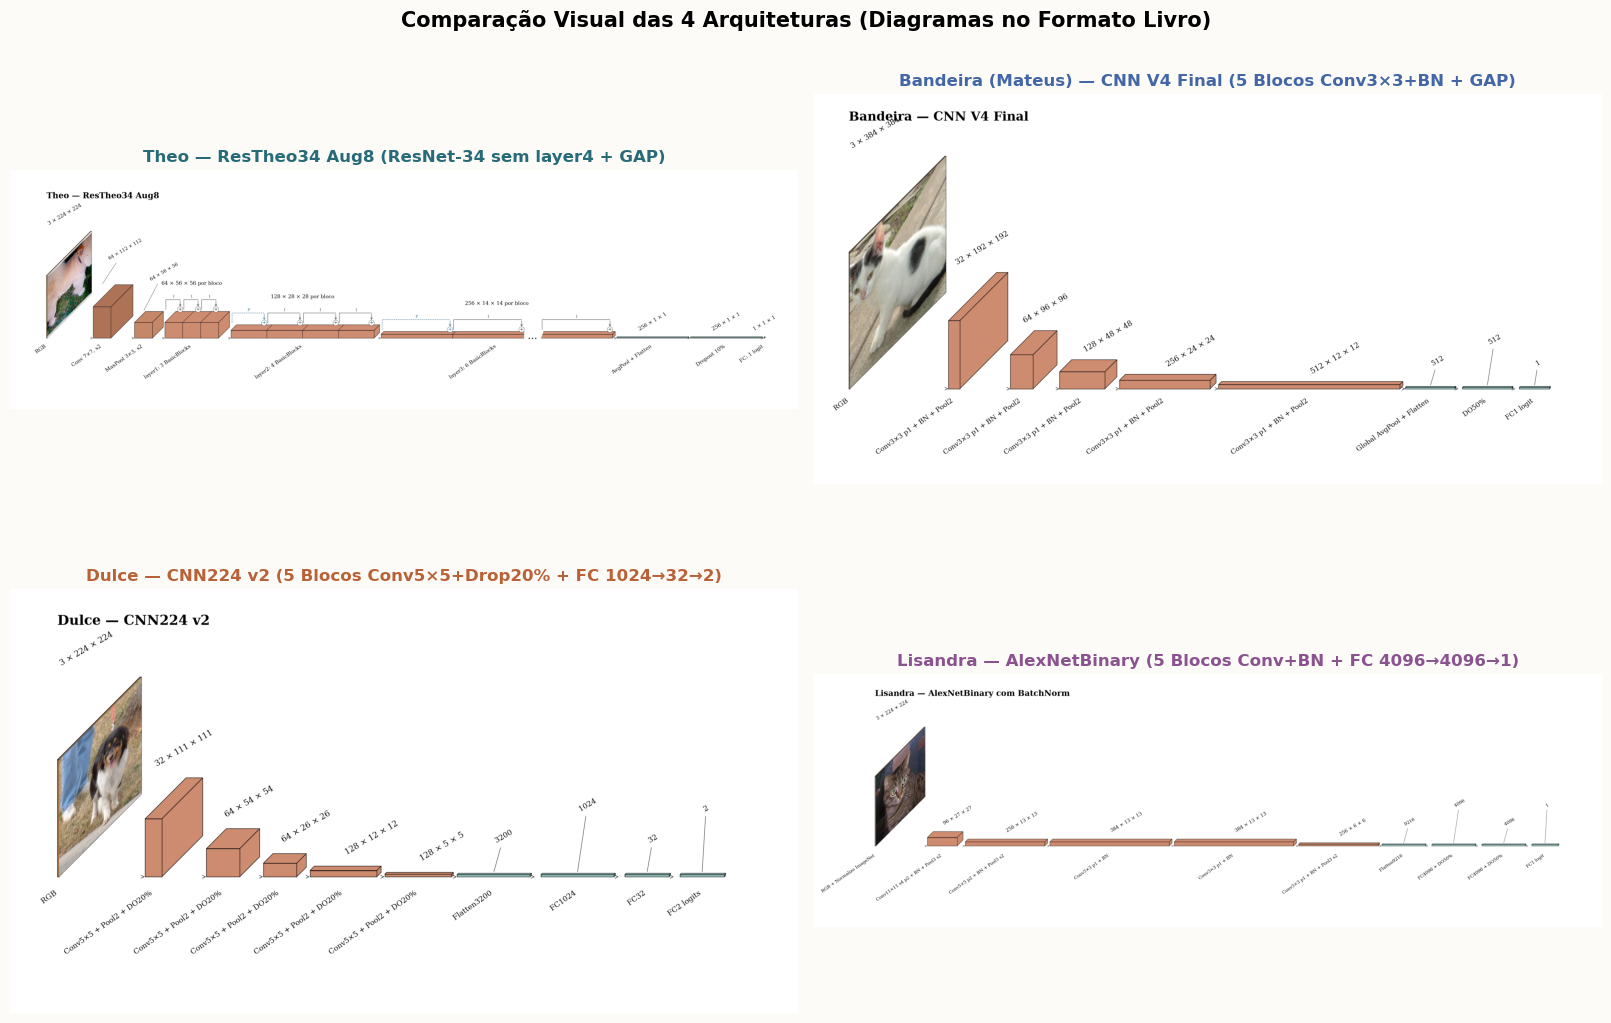

Modelo,Parâmetros Backbone,Parâmetros Cabeça,% na Cabeça,Total de Parâmetros,Treináveis na Fase Final,Tamanho do Peso
Theo (ResTheo34 Aug8),8.170.560,257,0.00%,8.170.817,8.170.817,31.20 MB
Bandeira (CNN V4 Final),1.570.560,513,0.03%,1.571.073,1.477.377,6.01 MB
Dulce (CNN224 v2),868.448,3.310.658,79.22%,4.179.106,4.179.106,15.58 MB
Lisandra (AlexNetBinary),3.755.392,54.534.145,93.56%,58.289.537,58.289.537,222.38 MB


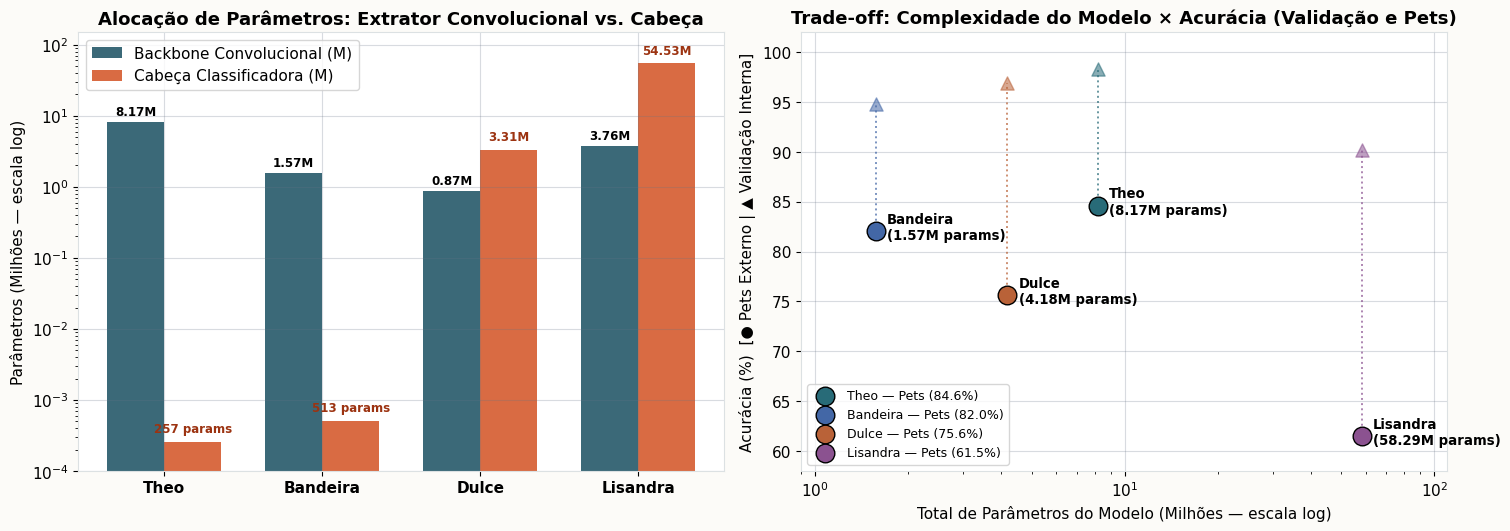

In [4]:
from PIL import Image

# Painel 2x2 com os diagramas de arquitetura no formato livro (gerados em Competicao/<Nome>/modelo principal/arquitetura_livro.png)
fig, axs = plt.subplots(2, 2, figsize=(16, 10.5), layout="constrained")
ordem_arq = [
    ("Theo — ResTheo34 Aug8 (ResNet-34 sem layer4 + GAP)", "Theo"),
    ("Bandeira (Mateus) — CNN V4 Final (5 Blocos Conv3×3+BN + GAP)", "Bandeira"),
    ("Dulce — CNN224 v2 (5 Blocos Conv5×5+Drop20% + FC 1024→32→2)", "Dulce"),
    ("Lisandra — AlexNetBinary (5 Blocos Conv+BN + FC 4096→4096→1)", "Lisandra"),
]

for ax, (titulo, nome) in zip(axs.flat, ordem_arq):
    img_path = ROOT / "Competicao" / nome / "modelo principal/arquitetura_livro.png"
    with Image.open(img_path) as im:
        ax.imshow(im)
    ax.set_title(titulo, fontsize=12, color=PALETA[nome], fontweight="bold")
    ax.axis("off")

fig.suptitle("Comparação Visual das 4 Arquiteturas (Diagramas no Formato Livro)", fontsize=15, fontweight="bold")
plt.show()

# Contagem exata de parâmetros por subsistema (Backbone Convolucional vs Cabeça Classificadora)
dados_complexidade = [
    {
        "Modelo": "Theo (ResTheo34 Aug8)",
        "Participante": "Theo",
        "Params Backbone (Conv/BN)": 8_170_560,
        "Params Cabeça (FC)": 257,
        "Params Totais": 8_170_817,
        "Params Treináveis (Fase Final)": 8_170_817,
        "Tamanho Checkpoint (MB)": 31.20,
        "Validação Interna (%)": 98.32,
        "Banco Pets (%)": 84.62,
    },
    {
        "Modelo": "Bandeira (CNN V4 Final)",
        "Participante": "Bandeira",
        "Params Backbone (Conv/BN)": 1_570_560,
        "Params Cabeça (FC)": 513,
        "Params Totais": 1_571_073,
        "Params Treináveis (Fase Final)": 1_477_377,
        "Tamanho Checkpoint (MB)": round((ROOT / "Mateus/data/best_model_4.0_Final.pth").stat().st_size / (1024**2), 2),
        "Validação Interna (%)": 94.76,
        "Banco Pets (%)": 82.05,  # 83.12% com crop proporcional autêntico; 79.22% com resize direto
    },
    {
        "Modelo": "Dulce (CNN224 v2)",
        "Participante": "Dulce",
        "Params Backbone (Conv/BN)": 868_448,
        "Params Cabeça (FC)": 3_310_658,
        "Params Totais": 4_179_106,
        "Params Treináveis (Fase Final)": 4_179_106,
        "Tamanho Checkpoint (MB)": round((ROOT / "Dulce/Cats vs Dogs/modelo_cats_and_dogs_224_v2.pt").stat().st_size / (1024**2), 2),
        "Validação Interna (%)": 96.90,
        "Banco Pets (%)": 75.64,
    },
    {
        "Modelo": "Lisandra (AlexNetBinary)",
        "Participante": "Lisandra",
        "Params Backbone (Conv/BN)": 3_755_392,
        "Params Cabeça (FC)": 54_534_145,
        "Params Totais": 58_289_537,
        "Params Treináveis (Fase Final)": 58_289_537,
        "Tamanho Checkpoint (MB)": round(233_178_729 / (1024**2), 2),
        "Validação Interna (%)": 90.16,
        "Banco Pets (%)": 61.54,
    },
]

tabela_comp_fmt = []
for d in dados_complexidade:
    pct_head = d["Params Cabeça (FC)"] / d["Params Totais"] * 100
    tabela_comp_fmt.append({
        "Modelo": d["Modelo"],
        "Parâmetros Backbone": f"{d['Params Backbone (Conv/BN)']:_}".replace("_", "."),
        "Parâmetros Cabeça": f"{d['Params Cabeça (FC)']:_}".replace("_", "."),
        "% na Cabeça": f"{pct_head:.2f}%",
        "Total de Parâmetros": f"{d['Params Totais']:_}".replace("_", "."),
        "Treináveis na Fase Final": f"{d['Params Treináveis (Fase Final)']:_}".replace("_", "."),
        "Tamanho do Peso": f"{d['Tamanho Checkpoint (MB)']:.2f} MB",
    })

_ = exibir_tabela(
    tabela_comp_fmt,
    titulo="Tabela 1B — Decomposição de Parâmetros (Backbone Convolucional vs. Cabeça Classificadora) e Tamanho em Disco",
)

fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")

# Subplot 1: Parâmetros no Backbone vs Cabeça (em milhões, escala logarítmica para comparar GAP vs FC)
nomes_c = [d["Participante"] for d in dados_complexidade]
backbone_m = [d["Params Backbone (Conv/BN)"] / 1e6 for d in dados_complexidade]
head_m = [d["Params Cabeça (FC)"] / 1e6 for d in dados_complexidade]
tot_m = [d["Params Totais"] / 1e6 for d in dados_complexidade]
x_pos = np.arange(len(nomes_c))

b_bk = axs[0].bar(x_pos - 0.18, backbone_m, width=0.36, color="#3b6978", label="Backbone Convolucional (M)")
b_hd = axs[0].bar(x_pos + 0.18, head_m, width=0.36, color="#d96b43", label="Cabeça Classificadora (M)")
axs[0].set_yscale("log")
axs[0].set_xticks(x_pos, nomes_c, fontweight="bold")
axs[0].set_ylabel("Parâmetros (Milhões — escala log)")
axs[0].set_title("Alocação de Parâmetros: Extrator Convolucional vs. Cabeça")
axs[0].set_ylim(1e-4, 150)
for bar, v in zip(b_bk, backbone_m):
    axs[0].text(bar.get_x() + bar.get_width() / 2, v * 1.25, f"{v:.2f}M", ha="center", fontsize=8.5, fontweight="bold")
for bar, d in zip(b_hd, dados_complexidade):
    v = d["Params Cabeça (FC)"]
    lbl = f"{v/1e6:.2f}M" if v >= 10000 else f"{v} params"
    axs[0].text(bar.get_x() + bar.get_width() / 2, (v / 1e6) * 1.35, lbl, ha="center", fontsize=8.5, fontweight="bold", color="#9c3311")
axs[0].legend(loc="upper left")

# Subplot 2: Eficiência de Parâmetros vs Acurácia no Banco Pets
for d in dados_complexidade:
    n = d["Participante"]
    px_val = d["Params Totais"] / 1e6
    py_pets = d["Banco Pets (%)"]
    py_val = d["Validação Interna (%)"]
    axs[1].scatter(px_val, py_pets, s=180, color=PALETA[n], edgecolors="black", zorder=5, label=f"{n} — Pets ({py_pets:.1f}%)")
    axs[1].scatter(px_val, py_val, s=90, color=PALETA[n], marker="^", alpha=0.55, zorder=4)
    axs[1].plot([px_val, px_val], [py_pets, py_val], color=PALETA[n], ls=":", lw=1.4, alpha=0.7)
    axs[1].annotate(f"{n}\n({px_val:.2f}M params)", (px_val, py_pets), xytext=(8, -6), textcoords="offset points", fontsize=9.5, fontweight="bold")

axs[1].set_xscale("log")
axs[1].set_xlim(0.9, 110)
axs[1].set_ylim(58, 102)
axs[1].set_xlabel("Total de Parâmetros do Modelo (Milhões — escala log)")
axs[1].set_ylabel("Acurácia (%)  [● Pets Externo | ▲ Validação Interna]")
axs[1].set_title("Trade-off: Complexidade do Modelo × Acurácia (Validação e Pets)")
axs[1].legend(loc="lower left", fontsize=9)

plt.show()


---
## 3. Evolução do Treinamento dos 4 Modelos (Curvas de Aprendizado)

Nesta seção, carregamos as séries temporais completas de treinamento e validação de cada participante:
* **Theo (`ResTheo34`)**: Tanto as 30 épocas da fase final `Aug8` quanto a linhagem histórica completa em 3 estágios (`Referência` 22 ép. → `Repetição` 35 ép. → `Aug8` 30 ép. = 87 épocas). Quando o CSV bruto local está ignorado pelo Git, os valores exatos são reconstruídos diretamente das polilinhas dos SVGs auditados em [`Competicao/coisas para apresentacao/Theo/`](Competicao/coisas%20para%20apresentacao/Theo/03_evolucao_aug8.svg).
* **Bandeira / Mateus (`CNN V4` → `V4 Final`)**: As 30 épocas do treinamento base ([`Mateus/data/training_history_4.0.csv`](Mateus/data/training_history_4.0.csv)) seguidas pelas 10 épocas de *fine-tuning* com blocos 1–3 congelados ([`Mateus/data/training_history_4.0_Final.csv`](Mateus/data/training_history_4.0_Final.csv)), além do histórico das versões anteriores (`V1`, `V2`, `V3`).
* **Dulce (`CNN224 v2`)**: As 120 épocas completas registradas em [`Dulce/Cats vs Dogs/historico/historico_treino_224_v2.json`](Dulce/Cats%20vs%20Dogs/historico/historico_treino_224_v2.json).
* **Lisandra (`AlexNetBinary`)**: As 10 épocas registradas em [`Lisandra/resultados_para_competicao/historico_epocas.csv`](Lisandra/resultados_para_competicao/historico_epocas.csv) antes da parada por *early stopping*.

In [5]:
def extrair_curvas_svg_theo(svg_path: Path, hi_loss_ref: float):
    """Extrai com precisão numérica as séries de treino e validação dos SVGs oficiais do Theo."""
    root_xml = ET.parse(svg_path).getroot()
    polylines = [
        el.attrib["points"]
        for el in root_xml.iter("{http://www.w3.org/2000/svg}polyline")
    ]
    # Ordem padrão no gerador: [acc_treino, acc_val, loss_treino, loss_val]
    def parse_pts(pts_str):
        return [tuple(map(float, p.split(","))) for p in pts_str.strip().split()]

    acc_tr = [0.4 + (705.0 - py) * 0.6 / 385.0 for _, py in parse_pts(polylines[0])]
    acc_va = [0.4 + (705.0 - py) * 0.6 / 385.0 for _, py in parse_pts(polylines[1])]
    loss_tr = [(705.0 - py) * hi_loss_ref / 385.0 for _, py in parse_pts(polylines[2])]
    loss_va = [(705.0 - py) * hi_loss_ref / 385.0 for _, py in parse_pts(polylines[3])]
    return {
        "epoca": list(range(1, len(acc_tr) + 1)),
        "acc_treino": acc_tr,
        "acc_val": acc_va,
        "loss_treino": loss_tr,
        "loss_val": loss_va,
    }


# 1. Theo — Aug8 (30 épocas) e evolução completa (87 épocas)
theo_csv_local = ROOT / "Competicao/Theo/modelo principal/treinamento_aug8/historico.csv"
if theo_csv_local.exists():
    with theo_csv_local.open() as f:
        rows_theo = list(csv.DictReader(f))
    hist_theo_aug8 = {
        "epoca": [int(r["epoca"]) for r in rows_theo],
        "acc_treino": [float(r["acuracia_treino"]) for r in rows_theo],
        "acc_val": [float(r["acuracia_validacao"]) for r in rows_theo],
        "loss_treino": [float(r["bce_treino"]) for r in rows_theo],
        "loss_val": [float(r["bce_validacao"]) for r in rows_theo],
    }
else:
    # Na época 29 do Aug8, bce_validacao = 0.053269144147634506 (py = 676.12 em 03_evolucao_aug8.svg)
    hi_aug8 = 0.053269144147634506 * 385.0 / (705.0 - 676.12)
    hist_theo_aug8 = extrair_curvas_svg_theo(APRES_DIR / "Theo/03_evolucao_aug8.svg", hi_aug8)

# Trajetória completa Theo (22 ép Referência + 35 ép Repetição + 30 ép Aug8 = 87 épocas)
hi_comp = 0.053269144147634506 * 385.0 / (705.0 - 664.26)
hist_theo_completo = extrair_curvas_svg_theo(APRES_DIR / "Theo/04_evolucao_completa.svg", hi_comp)

# 2. Mateus / Bandeira — V4 (30 épocas) + V4 Final (10 épocas = 40 épocas contínuas)
with (ROOT / "Mateus/data/training_history_4.0.csv").open() as f:
    r_v4 = list(csv.DictReader(f))
with (ROOT / "Mateus/data/training_history_4.0_Final.csv").open() as f:
    r_v4f = list(csv.DictReader(f))

hist_bandeira = {
    "epoca": list(range(1, len(r_v4) + len(r_v4f) + 1)),
    "acc_treino": [float(r["train_acc"]) for r in r_v4] + [float(r["train_acc"]) for r in r_v4f],
    "acc_val": [float(r["val_acc"]) for r in r_v4] + [float(r["val_acc"]) for r in r_v4f],
    "loss_treino": [float(r["train_loss"]) for r in r_v4] + [float(r["train_loss"]) for r in r_v4f],
    "loss_val": [float(r["val_loss"]) for r in r_v4] + [float(r["val_loss"]) for r in r_v4f],
}

# 3. Dulce — CNN224 v2 (120 épocas)
raw_dulce = json.loads((ROOT / "Dulce/Cats vs Dogs/historico/historico_treino_224_v2.json").read_text())
hist_dulce = {
    "epoca": list(range(1, len(raw_dulce["acc_treino"]) + 1)),
    "acc_treino": [float(x) for x in raw_dulce["acc_treino"]],
    "acc_val": [float(x) for x in raw_dulce["acc_val"]],
    "loss_treino": [float(x) for x in raw_dulce["perda_treino"]],
    "loss_val": [float(x) for x in raw_dulce["perda_val"]],
}

# 4. Lisandra — AlexNetBinary (10 épocas)
with (ROOT / "Lisandra/resultados_para_competicao/historico_epocas.csv").open(encoding="utf-8-sig") as f:
    r_lis = list(csv.DictReader(f))
hist_lisandra = {
    "epoca": [int(r["epoca"]) for r in r_lis],
    "acc_treino": [float(r["acuracia_treino"]) for r in r_lis],
    "acc_val": [float(r["acuracia_validacao"]) for r in r_lis],
    "loss_treino": [float(r["perda_treino"]) for r in r_lis],
    "loss_val": [float(r["perda_validacao"]) for r in r_lis],
}

print("Séries de treinamento carregadas com sucesso:")
print(f"  - Theo Aug8: {len(hist_theo_aug8['epoca'])} épocas (melhor val_acc = {max(hist_theo_aug8['acc_val'])*100:.2f}% na época 29)")
print(f"  - Bandeira V4 + V4 Final: {len(hist_bandeira['epoca'])} épocas (checkpoint ép. 40: val_acc = {hist_bandeira['acc_val'][-1]*100:.2f}%, val_loss = {hist_bandeira['loss_val'][-1]:.4f})")
print(f"  - Dulce CNN224 v2: {len(hist_dulce['epoca'])} épocas (melhor val_acc = {max(hist_dulce['acc_val'])*100:.2f}% na época {np.argmax(hist_dulce['acc_val'])+1})")
print(f"  - Lisandra AlexNetBinary: {len(hist_lisandra['epoca'])} épocas (checkpoint ép. 5: val_acc = {hist_lisandra['acc_val'][4]*100:.2f}%, menor val_loss = {hist_lisandra['loss_val'][4]:.4f})")

Séries de treinamento carregadas com sucesso:
  - Theo Aug8: 30 épocas (melhor val_acc = 98.32% na época 29)
  - Bandeira V4 + V4 Final: 40 épocas (checkpoint ép. 40: val_acc = 94.76%, val_loss = 0.1336)
  - Dulce CNN224 v2: 120 épocas (melhor val_acc = 96.90% na época 112)
  - Lisandra AlexNetBinary: 10 épocas (checkpoint ép. 5: val_acc = 90.16%, menor val_loss = 0.2237)


### 3.1. Painel Individual (4×2) — Curvas de Acurácia e Perda (Treino vs. Validação)

Abaixo visualizamos o comportamento de convergência de cada modelo em seu próprio conjunto de treinamento e validação, destacando:
* O **checkpoint selecionado** por cada autor (linha tracejada verde);
* A **transição para o Fine-Tuning** na época 30 do modelo de **Mateus / Bandeira** (linha tracejada roxa), onde o congelamento dos blocos 1–3 e a redução do learning rate (`1e-5`) estabilizaram a curva de validação eliminando as oscilações vistas na fase inicial;
* A **diferença de critério** no modelo da **Lisandra** entre a época 5 (menor `val_loss = 0,2237`, `val_acc = 90,16%`) e a época 8 (pico de `val_acc = 91,08%`, mas já com início de subida na perda).

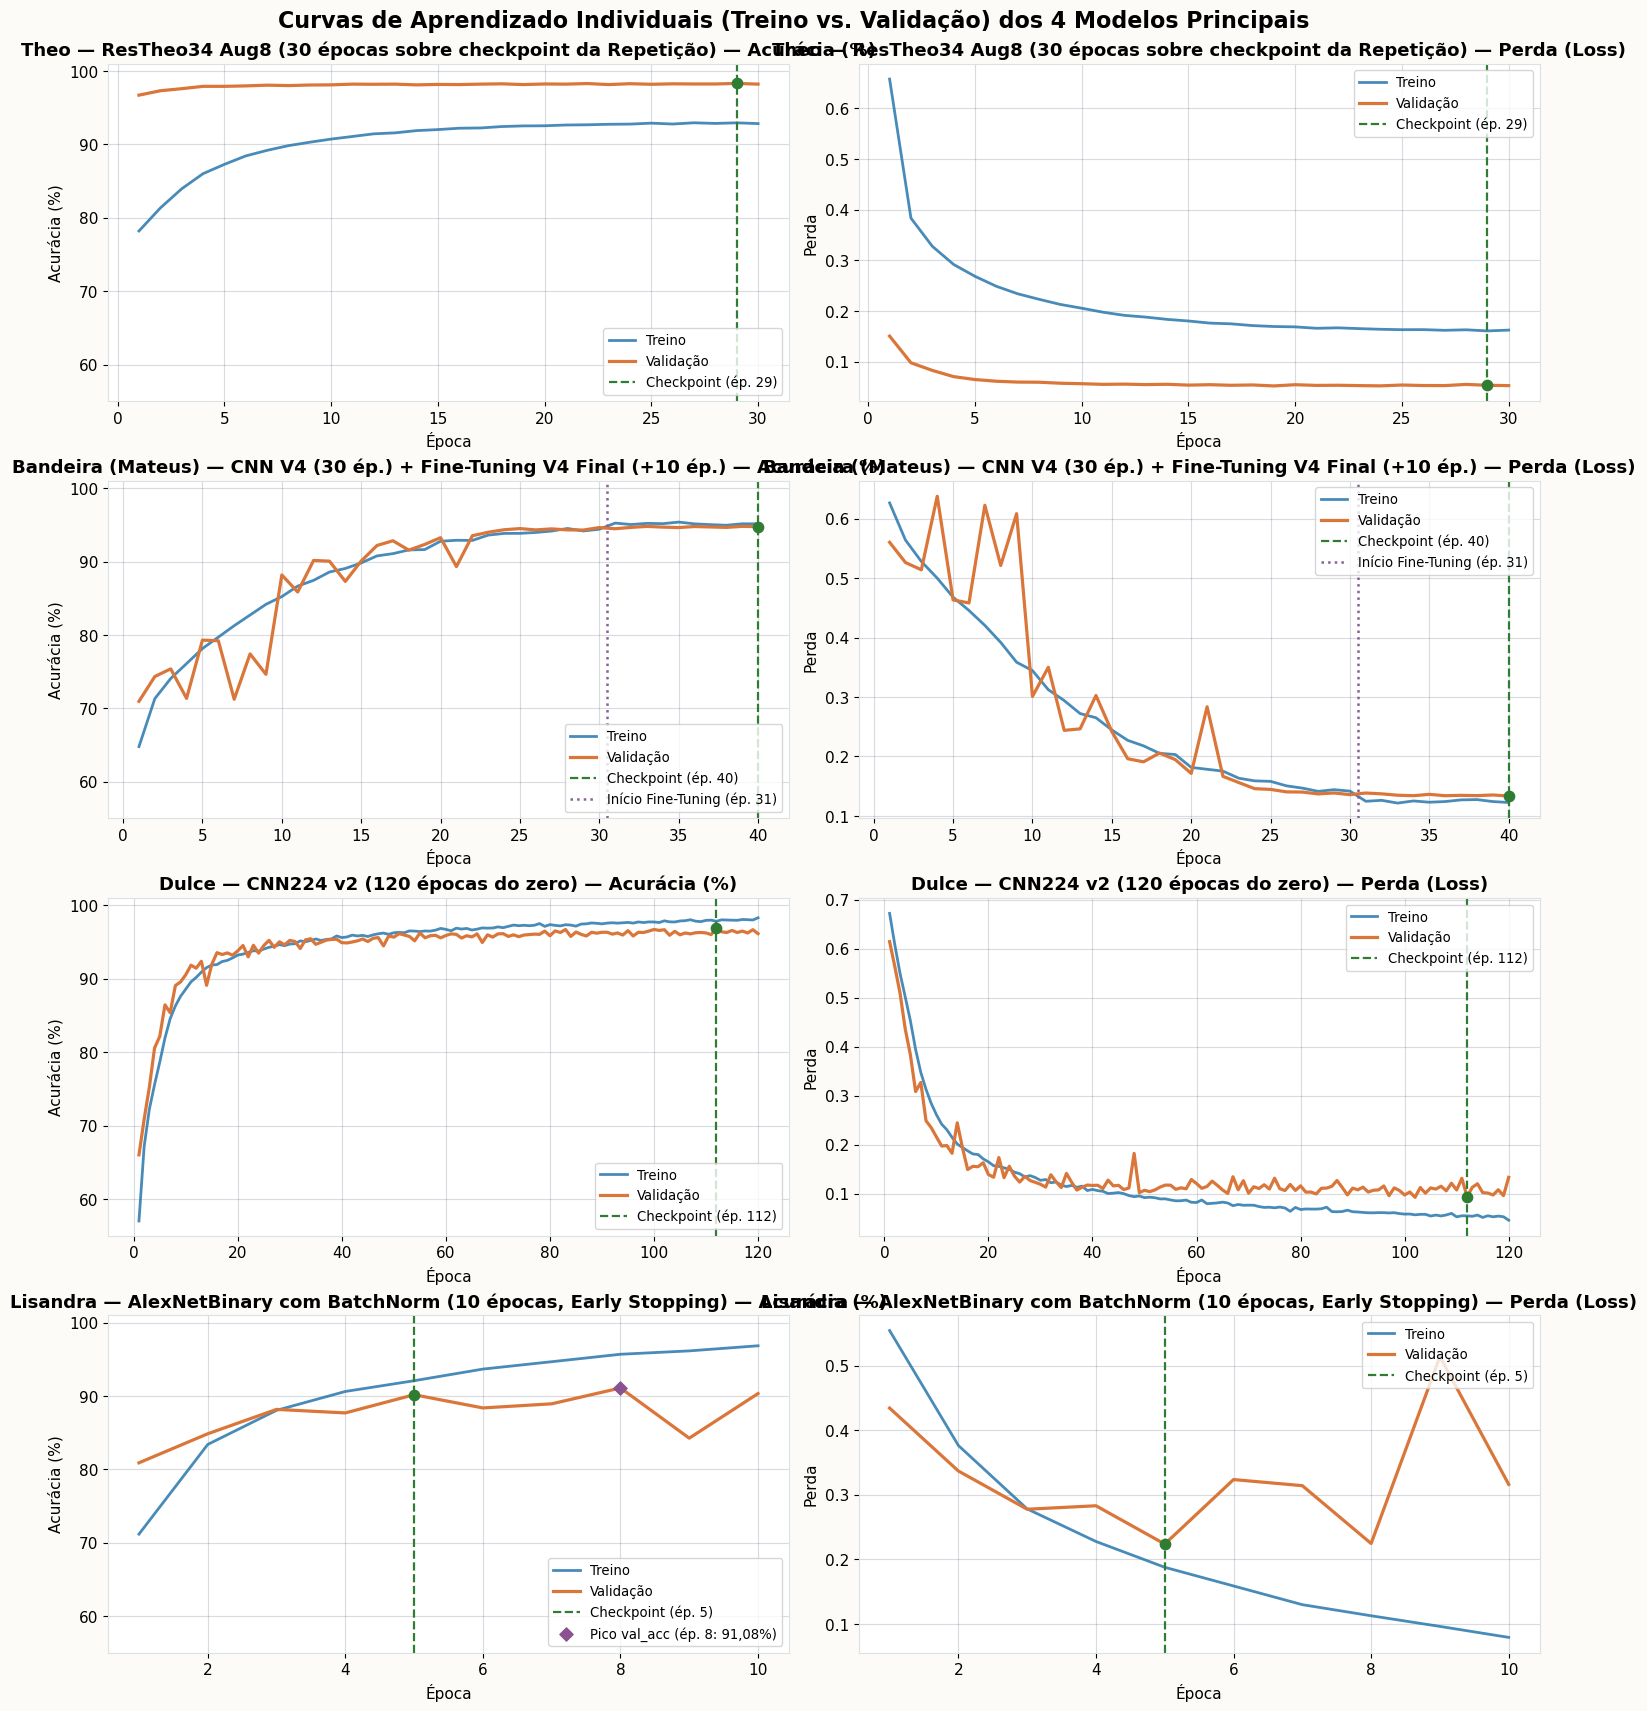

In [6]:
fig, axs = plt.subplots(4, 2, figsize=(15, 17), layout="constrained")

configs_painel = [
    ("Theo — ResTheo34 Aug8 (30 épocas sobre checkpoint da Repetição)", hist_theo_aug8, 29, PALETA["Theo"], None),
    ("Bandeira (Mateus) — CNN V4 (30 ép.) + Fine-Tuning V4 Final (+10 ép.)", hist_bandeira, 40, PALETA["Bandeira"], 30.5),
    ("Dulce — CNN224 v2 (120 épocas do zero)", hist_dulce, 112, PALETA["Dulce"], None),
    ("Lisandra — AlexNetBinary com BatchNorm (10 épocas, Early Stopping)", hist_lisandra, 5, PALETA["Lisandra"], None),
]

for row_idx, (titulo, h, ckpt_ep, cor, split_ep) in enumerate(configs_painel):
    ep = h["epoca"]
    ax_acc, ax_loss = axs[row_idx, 0], axs[row_idx, 1]

    # Acurácia
    ax_acc.plot(ep, [x * 100 for x in h["acc_treino"]], label="Treino", color="#2877ad", lw=2, alpha=0.85)
    ax_acc.plot(ep, [x * 100 for x in h["acc_val"]], label="Validação", color="#da7639", lw=2.3)
    ax_acc.axvline(ckpt_ep, color="#2e7d32", ls="--", lw=1.6, label=f"Checkpoint (ép. {ckpt_ep})")
    ax_acc.scatter([ckpt_ep], [h["acc_val"][ckpt_ep - 1] * 100], color="#2e7d32", s=55, zorder=5)
    if split_ep:
        ax_acc.axvline(split_ep, color="#866294", ls=":", lw=1.8, label="Início Fine-Tuning (ép. 31)")
    if "Lisandra" in titulo:
        ax_acc.scatter([8], [h["acc_val"][7] * 100], color="#8b5290", marker="D", s=45, zorder=5, label="Pico val_acc (ép. 8: 91,08%)")
    ax_acc.set_title(f"{titulo} — Acurácia (%)")
    ax_acc.set_xlabel("Época")
    ax_acc.set_ylabel("Acurácia (%)")
    ax_acc.set_ylim(55, 101)
    ax_acc.legend(loc="lower right", fontsize=9.5)

    # Perda
    ax_loss.plot(ep, h["loss_treino"], label="Treino", color="#2877ad", lw=2, alpha=0.85)
    ax_loss.plot(ep, h["loss_val"], label="Validação", color="#da7639", lw=2.3)
    ax_loss.axvline(ckpt_ep, color="#2e7d32", ls="--", lw=1.6, label=f"Checkpoint (ép. {ckpt_ep})")
    ax_loss.scatter([ckpt_ep], [h["loss_val"][ckpt_ep - 1]], color="#2e7d32", s=55, zorder=5)
    if split_ep:
        ax_loss.axvline(split_ep, color="#866294", ls=":", lw=1.8, label="Início Fine-Tuning (ép. 31)")
    ax_loss.set_title(f"{titulo} — Perda (Loss)")
    ax_loss.set_xlabel("Época")
    ax_loss.set_ylabel("Perda")
    ax_loss.legend(loc="upper right", fontsize=9.5)

fig.suptitle("Curvas de Aprendizado Individuais (Treino vs. Validação) dos 4 Modelos Principais", fontsize=16, fontweight="bold")
plt.show()

### 3.2. Comparação Sobreposta das Curvas de Validação e Evolução Multi-Estágio

Para visualizar diretamente a velocidade de convergência, estabilidade e patamar atingido em cada validação, plotamos:
1. As curvas de **Acurácia de Validação** e **Perda de Validação** sobrepostas;
2. A **evolução das versões experimentais** de cada autor (mostrando o ganho progressivo de engenharia ao longo do projeto).

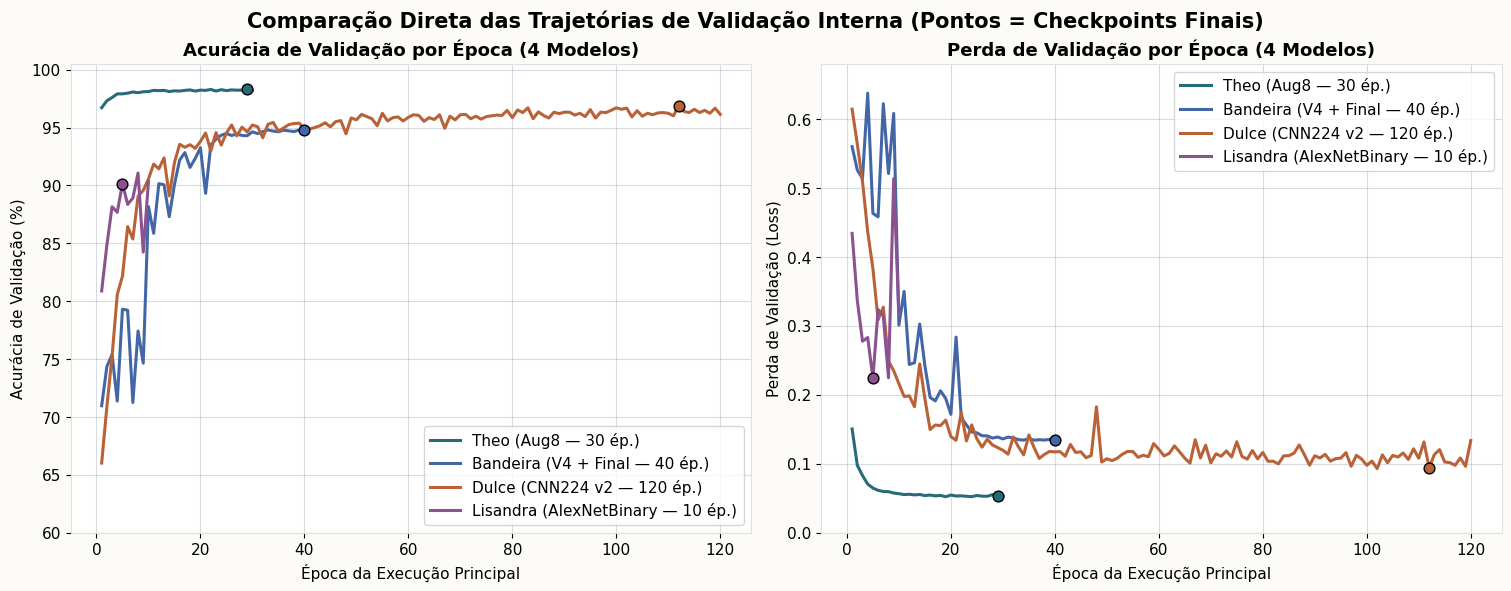

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.8), layout="constrained")

series_sobrepostas = [
    ("Theo (Aug8 — 30 ép.)", hist_theo_aug8, PALETA["Theo"], 29),
    ("Bandeira (V4 + Final — 40 ép.)", hist_bandeira, PALETA["Bandeira"], 40),
    ("Dulce (CNN224 v2 — 120 ép.)", hist_dulce, PALETA["Dulce"], 112),
    ("Lisandra (AlexNetBinary — 10 ép.)", hist_lisandra, PALETA["Lisandra"], 5),
]

for label, h, cor, ckpt in series_sobrepostas:
    axs[0].plot(h["epoca"], [v * 100 for v in h["acc_val"]], label=label, color=cor, lw=2.2)
    axs[0].scatter([ckpt], [h["acc_val"][ckpt - 1] * 100], color=cor, s=60, edgecolors="black", zorder=5)

    axs[1].plot(h["epoca"], h["loss_val"], label=label, color=cor, lw=2.2)
    axs[1].scatter([ckpt], [h["loss_val"][ckpt - 1]], color=cor, s=60, edgecolors="black", zorder=5)

axs[0].set_title("Acurácia de Validação por Época (4 Modelos)")
axs[0].set_xlabel("Época da Execução Principal")
axs[0].set_ylabel("Acurácia de Validação (%)")
axs[0].set_ylim(60, 100.5)
axs[0].legend(loc="lower right")

axs[1].set_title("Perda de Validação por Época (4 Modelos)")
axs[1].set_xlabel("Época da Execução Principal")
axs[1].set_ylabel("Perda de Validação (Loss)")
axs[1].set_ylim(0, 0.68)
axs[1].legend(loc="upper right")

fig.suptitle("Comparação Direta das Trajetórias de Validação Interna (Pontos = Checkpoints Finais)", fontsize=15, fontweight="bold")
plt.show()

### 3.3. Progressão Histórica de Versões e Experimentos por Participante

Tanto **Theo** quanto **Mateus (Bandeira)** e **Dulce** realizaram múltiplos ciclos iterativos até chegar ao modelo principal:
* **Theo**: `Referência` (96,86%) → `Repetição` (97,34% na época 33) → `Aug8` (**98,32%** na época 29).
* **Bandeira (Mateus)**: `V1 Baseline` (90,94%, 15 ép.) → `V2 Augmentation/Scheduler` (91,56%, 22 ép.) → `V3 Arquitetura 5 blocos + Resolução 384` (94,50%, 30 ép.) → `V4 Regularização e Limpeza` (94,64%, 30 ép.) → `V4 Final Fine-Tuning` (**94,76%** no critério de menor `val_loss`, com pico de **94,80%** nas épocas 3 e 9).
* **Dulce**: `Série 100 épocas` (96,09% val / 96,10% teste) → `CNN224` (95,83% val / 95,84% teste) → `CNN224 v2` (**96,90%** val / **96,43%** teste, modelo principal do zero) e experimento adicional com `ResNet18` pré-treinada (99,1% val / 98,8% teste em 5 épocas).

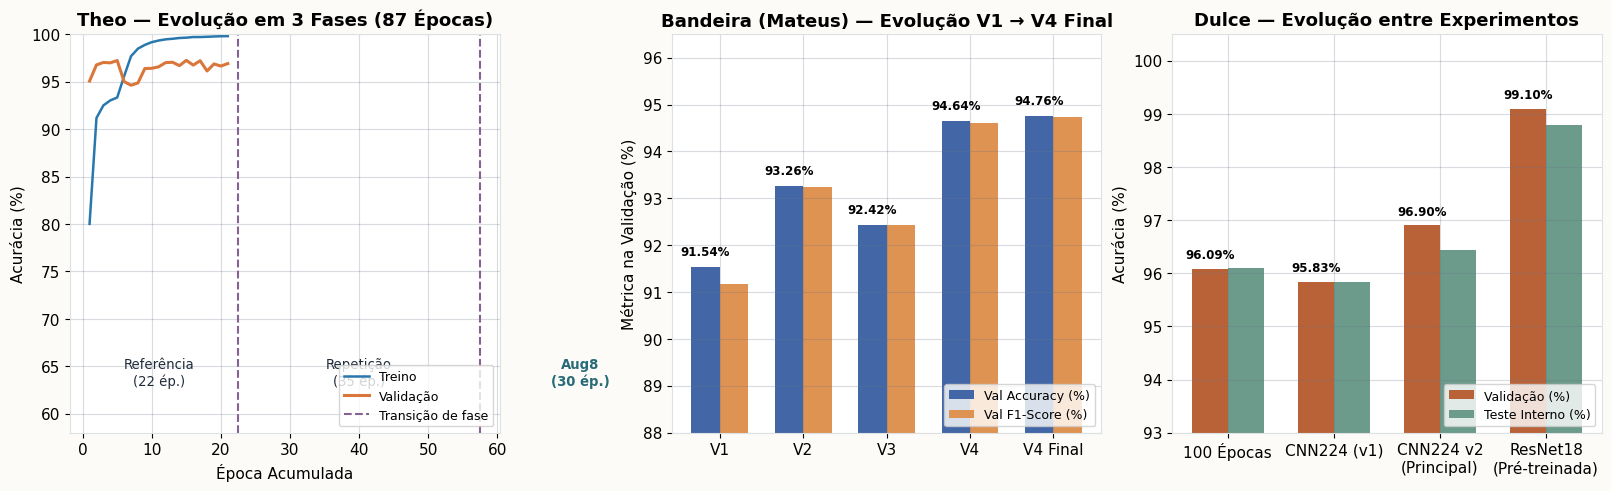

In [8]:
# Carrega históricos V1..V3 do Mateus para mostrar evolução completa V1 -> V4 Final
def resumo_hist_mateus(nome_csv, pred_csv):
    with (ROOT / "Mateus/data" / nome_csv).open() as f:
        rows = list(csv.DictReader(f))
    best_loss_row = min(rows, key=lambda r: float(r["val_loss"]))
    best_acc_row = max(rows, key=lambda r: float(r["val_acc"]))
    with (ROOT / "Mateus/data" / pred_csv).open() as f:
        preds = list(csv.DictReader(f))
    tp = sum(1 for r in preds if int(float(r["y_true"])) == 1 and int(float(r["y_pred"])) == 1)
    fp = sum(1 for r in preds if int(float(r["y_true"])) == 0 and int(float(r["y_pred"])) == 1)
    fn = sum(1 for r in preds if int(float(r["y_true"])) == 1 and int(float(r["y_pred"])) == 0)
    f1_val = 2 * tp / (2 * tp + fp + fn) * 100
    return {
        "epocas": len(rows),
        "epoca_ckpt": int(best_loss_row["epoch"]),
        "val_acc_ckpt": float(best_loss_row["val_acc"]) * 100,
        "val_loss_ckpt": float(best_loss_row["val_loss"]),
        "val_f1_ckpt": f1_val,
        "pico_val_acc": float(best_acc_row["val_acc"]) * 100,
    }


evolucao_mateus = [
    {"Versão": "V1 (Baseline 224×224)", **resumo_hist_mateus("training_history.csv", "val_predictions.csv")},
    {"Versão": "V2 (+Augmentation & Cosine)", **resumo_hist_mateus("training_history_2.0.csv", "val_predictions_2.0.csv")},
    {"Versão": "V3 (5 Blocos + 384×384)", **resumo_hist_mateus("training_history_3.0.csv", "val_predictions_3.0.csv")},
    {"Versão": "V4 (Filtro de Dados + Reg.)", **resumo_hist_mateus("training_history_4.0.csv", "val_predictions_4.0.csv")},
    {"Versão": "V4 Final (+10 ép. Fine-Tuning)", **resumo_hist_mateus("training_history_4.0_Final.csv", "val_predictions_4.0_Final.csv")},
]

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")

# Subplot 1: Linhagem 87 épocas Theo
ep_t = hist_theo_completo["epoca"]
axs[0].plot(ep_t, [v * 100 for v in hist_theo_completo["acc_treino"]], color="#2877ad", lw=1.8, label="Treino")
axs[0].plot(ep_t, [v * 100 for v in hist_theo_completo["acc_val"]], color="#da7639", lw=2.2, label="Validação")
axs[0].axvline(22.5, color="#866294", ls="--", lw=1.5, label="Transição de fase")
axs[0].axvline(57.5, color="#866294", ls="--", lw=1.5)
axs[0].text(11, 63, "Referência\n(22 ép.)", ha="center", fontsize=9.5, color="#202c39")
axs[0].text(40, 63, "Repetição\n(35 ép.)", ha="center", fontsize=9.5, color="#202c39")
axs[0].text(72, 63, "Aug8\n(30 ép.)", ha="center", fontsize=9.5, fontweight="bold", color=PALETA["Theo"])
axs[0].set_title("Theo — Evolução em 3 Fases (87 Épocas)")
axs[0].set_xlabel("Época Acumulada")
axs[0].set_ylabel("Acurácia (%)")
axs[0].set_ylim(58, 100)
axs[0].legend(loc="lower right", fontsize=9)

# Subplot 2: Evolução V1 -> V4 Final do Mateus (Bandeira)
nomes_m = ["V1", "V2", "V3", "V4", "V4 Final"]
accs_m = [r["val_acc_ckpt"] for r in evolucao_mateus]
f1s_m = [r["val_f1_ckpt"] for r in evolucao_mateus]
x_m = np.arange(len(nomes_m))
bars_m = axs[1].bar(x_m - 0.17, accs_m, width=0.34, color=PALETA["Bandeira"], label="Val Accuracy (%)")
axs[1].bar(x_m + 0.17, f1s_m, width=0.34, color="#df9352", label="Val F1-Score (%)")
for b in bars_m:
    axs[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.25, f"{b.get_height():.2f}%", ha="center", fontsize=8.5, fontweight="bold")
axs[1].set_xticks(x_m, nomes_m)
axs[1].set_ylim(88, 96.5)
axs[1].set_title("Bandeira (Mateus) — Evolução V1 → V4 Final")
axs[1].set_ylabel("Métrica na Validação (%)")
axs[1].legend(loc="lower right", fontsize=9)

# Subplot 3: Experimentos da Dulce
nomes_d = ["100 Épocas", "CNN224 (v1)", "CNN224 v2\n(Principal)", "ResNet18\n(Pré-treinada)"]
val_d = [96.09, 95.83, 96.90, 99.10]
test_d = [96.10, 95.84, 96.43, 98.80]
x_d = np.arange(len(nomes_d))
b_d1 = axs[2].bar(x_d - 0.17, val_d, width=0.34, color=PALETA["Dulce"], label="Validação (%)")
b_d2 = axs[2].bar(x_d + 0.17, test_d, width=0.34, color="#6c9a8b", label="Teste Interno (%)")
for b in b_d1:
    axs[2].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.2, f"{b.get_height():.2f}%", ha="center", fontsize=8.5, fontweight="bold")
axs[2].set_xticks(x_d, nomes_d)
axs[2].set_ylim(93, 100.5)
axs[2].set_title("Dulce — Evolução entre Experimentos")
axs[2].set_ylabel("Acurácia (%)")
axs[2].legend(loc="lower right", fontsize=9)

plt.show()

---
## 4. Avaliação Detalhada nas Validações e Testes Internos

Antes de analisar o benchmark externo `Pets`, inspecionamos as métricas detalhadas obtidas pelos modelos dentro de suas respectivas divisões de validação/teste, utilizando os arquivos de predições e resumos salvos no repositório:
* **Mateus (Bandeira)**: 5.000 predições de validação salvas em [`Mateus/data/val_predictions_4.0.csv`](Mateus/data/val_predictions_4.0.csv) e [`Mateus/data/val_predictions_4.0_Final.csv`](Mateus/data/val_predictions_4.0_Final.csv) (2.500 gatos e 2.500 cães);
* **Dulce**: Matriz de confusão e métricas em **3.723 imagens de teste** consolidadas em [`Competicao/Dulce/modelo principal/resumo_resultado.json`](Competicao/Dulce/modelo%20principal/resumo_resultado.json).

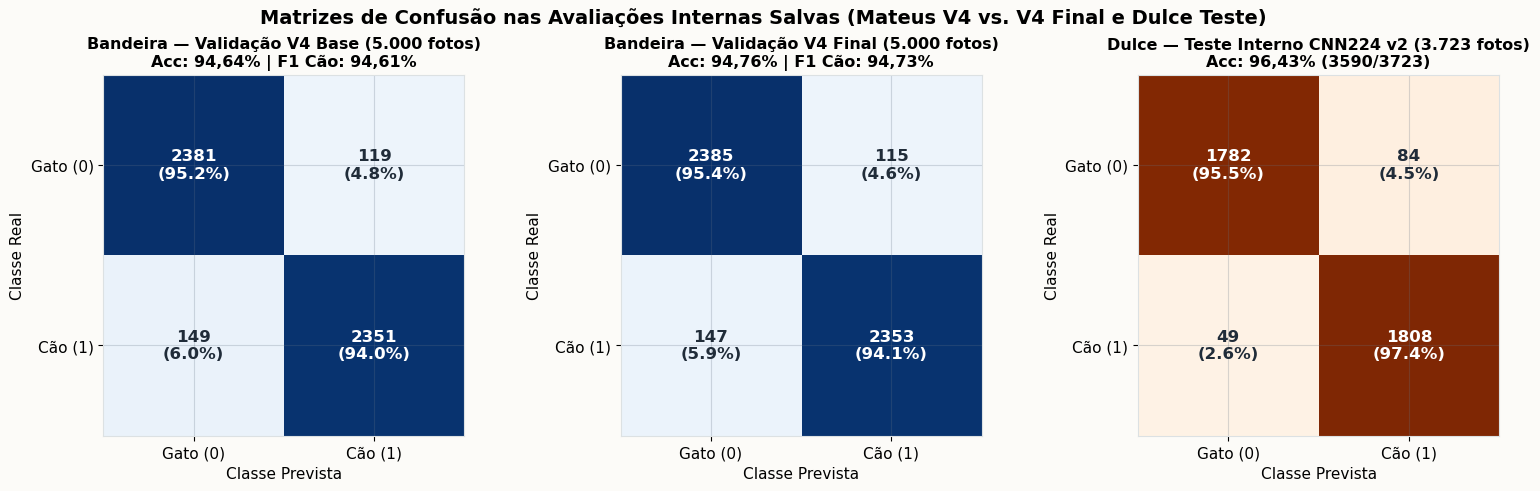

Modelo / Conjunto,Acurácia,Precisão Gato,Recall Gato,Precisão Cão,Recall Cão,F1-Score Cão
Bandeira — CNN V4 Base (Validação 5.000),94.64%,94.11%,95.24%,95.18%,94.04%,94.61%
Bandeira — CNN V4 Final (Validação 5.000),94.76%,94.19%,95.40%,95.34%,94.12%,94.73%
Dulce — CNN224 v2 (Teste 3.723),96.43%,97.20%,95.50%,95.70%,97.40%,96.50%


In [9]:
def calcular_metricas_predicoes_csv(csv_path: Path):
    with csv_path.open() as f:
        rows = list(csv.DictReader(f))
    tn = fp = fn = tp = 0
    for r in rows:
        y = int(float(r["y_true"]))
        p = int(float(r["y_pred"]))
        tn += int(y == 0 and p == 0)
        fp += int(y == 0 and p == 1)
        fn += int(y == 1 and p == 0)
        tp += int(y == 1 and p == 1)
    total = len(rows)
    acc = (tp + tn) / total
    prec_dog = tp / (tp + fp)
    rec_dog = tp / (tp + fn)
    f1_dog = 2 * tp / (2 * tp + fp + fn)
    prec_cat = tn / (tn + fn)
    rec_cat = tn / (tn + fp)
    f1_cat = 2 * tn / (2 * tn + fp + fn)
    return {
        "total": total,
        "matriz": [[tn, fp], [fn, tp]],
        "acc": acc,
        "prec_cat": prec_cat,
        "rec_cat": rec_cat,
        "f1_cat": f1_cat,
        "prec_dog": prec_dog,
        "rec_dog": rec_dog,
        "f1_dog": f1_dog,
    }


m_v4 = calcular_metricas_predicoes_csv(ROOT / "Mateus/data/val_predictions_4.0.csv")
m_v4_final = calcular_metricas_predicoes_csv(ROOT / "Mateus/data/val_predictions_4.0_Final.csv")
resumo_dulce = json.loads((ROOT / "Competicao/Dulce/modelo principal/resumo_resultado.json").read_text())

# Métricas do conjunto de teste interno da Dulce (3.723 imagens) preservadas na saída de cats_and_dogs_224_v2.ipynb (células 38 e 40)
# Acertos: 3590/3723 (96.43%) | Gato: recall 95.5%, precisão 97.2% | Cachorro: recall 97.4%, precisão 95.7%
teste_dulce = {
    "acuracia": 3590 / 3723,
    "precisao": {"Cat": 0.972, "Dog": 0.957},
    "recall": {"Cat": 0.955, "Dog": 0.974},
    "matriz_confusao": [[1782, 84], [49, 1808]],
}

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.8), layout="constrained")

matrizes_internas = [
    ("Bandeira — Validação V4 Base (5.000 fotos)\nAcc: 94,64% | F1 Cão: 94,61%", m_v4["matriz"], "Blues"),
    ("Bandeira — Validação V4 Final (5.000 fotos)\nAcc: 94,76% | F1 Cão: 94,73%", m_v4_final["matriz"], "Blues"),
    ("Dulce — Teste Interno CNN224 v2 (3.723 fotos)\nAcc: 96,43% (3590/3723)", teste_dulce["matriz_confusao"], "Oranges"),
]

for ax, (titulo, mat, cmap) in zip(axs, matrizes_internas):
    arr = np.array(mat)
    ax.imshow(arr, cmap=cmap, vmin=0, vmax=arr.max())
    ax.set_xticks([0, 1], ["Gato (0)", "Cão (1)"])
    ax.set_yticks([0, 1], ["Gato (0)", "Cão (1)"])
    ax.set_xlabel("Classe Prevista")
    ax.set_ylabel("Classe Real")
    ax.set_title(titulo, fontsize=11.5)
    row_sums = arr.sum(axis=1, keepdims=True)
    for i in range(2):
        for j in range(2):
            pct_row = arr[i, j] / row_sums[i, 0] * 100
            cor_txt = "white" if arr[i, j] > arr.max() * 0.55 else "#202c39"
            ax.text(j, i, f"{arr[i, j]}\n({pct_row:.1f}%)", ha="center", va="center", fontsize=12, fontweight="bold", color=cor_txt)

fig.suptitle("Matrizes de Confusão nas Avaliações Internas Salvas (Mateus V4 vs. V4 Final e Dulce Teste)", fontsize=14, fontweight="bold")
plt.show()

tabela_interna_detalhada = [
    {
        "Modelo / Conjunto": "Bandeira — CNN V4 Base (Validação 5.000)",
        "Acurácia": f"{m_v4['acc']*100:.2f}%",
        "Precisão Gato": f"{m_v4['prec_cat']*100:.2f}%",
        "Recall Gato": f"{m_v4['rec_cat']*100:.2f}%",
        "Precisão Cão": f"{m_v4['prec_dog']*100:.2f}%",
        "Recall Cão": f"{m_v4['rec_dog']*100:.2f}%",
        "F1-Score Cão": f"{m_v4['f1_dog']*100:.2f}%",
    },
    {
        "Modelo / Conjunto": "Bandeira — CNN V4 Final (Validação 5.000)",
        "Acurácia": f"{m_v4_final['acc']*100:.2f}%",
        "Precisão Gato": f"{m_v4_final['prec_cat']*100:.2f}%",
        "Recall Gato": f"{m_v4_final['rec_cat']*100:.2f}%",
        "Precisão Cão": f"{m_v4_final['prec_dog']*100:.2f}%",
        "Recall Cão": f"{m_v4_final['rec_dog']*100:.2f}%",
        "F1-Score Cão": f"{m_v4_final['f1_dog']*100:.2f}%",
    },
    {
        "Modelo / Conjunto": "Dulce — CNN224 v2 (Teste 3.723)",
        "Acurácia": f"{teste_dulce['acuracia']*100:.2f}%",
        "Precisão Gato": f"{teste_dulce['precisao']['Cat']*100:.2f}%",
        "Recall Gato": f"{teste_dulce['recall']['Cat']*100:.2f}%",
        "Precisão Cão": f"{teste_dulce['precisao']['Dog']*100:.2f}%",
        "Recall Cão": f"{teste_dulce['recall']['Dog']*100:.2f}%",
        "F1-Score Cão": f"{2*1808/(2*1808+82+49)*100:.2f}%",
    },
]
_ = exibir_tabela(tabela_interna_detalhada, titulo="Tabela 2 — Métricas por Classe nas Predições Internas Salvas")

### 4.1. Curvas ROC, Calibração de Probabilidades e Redução de Erros Críticos (`Mateus V1 → V4 Final`)

Aproveitando que os 5 conjuntos de predições de validação do projeto **Mateus / Bandeira** (`V1`, `V2`, `V3`, `V4` e `V4 Final`) preservam as probabilidades contínuas (`y_prob`) para todas as 5.000 imagens de validação, analisamos:
1. A evolução da **Curva ROC e AUC** da `V1` até a `V4 Final`;
2. O **histograma de calibração das probabilidades previstas** na `V4 Final`, mostrando a concentração de confiança próxima de `0,0` (Gato) e `1,0` (Cão) e a redução de erros de altíssima confiança.

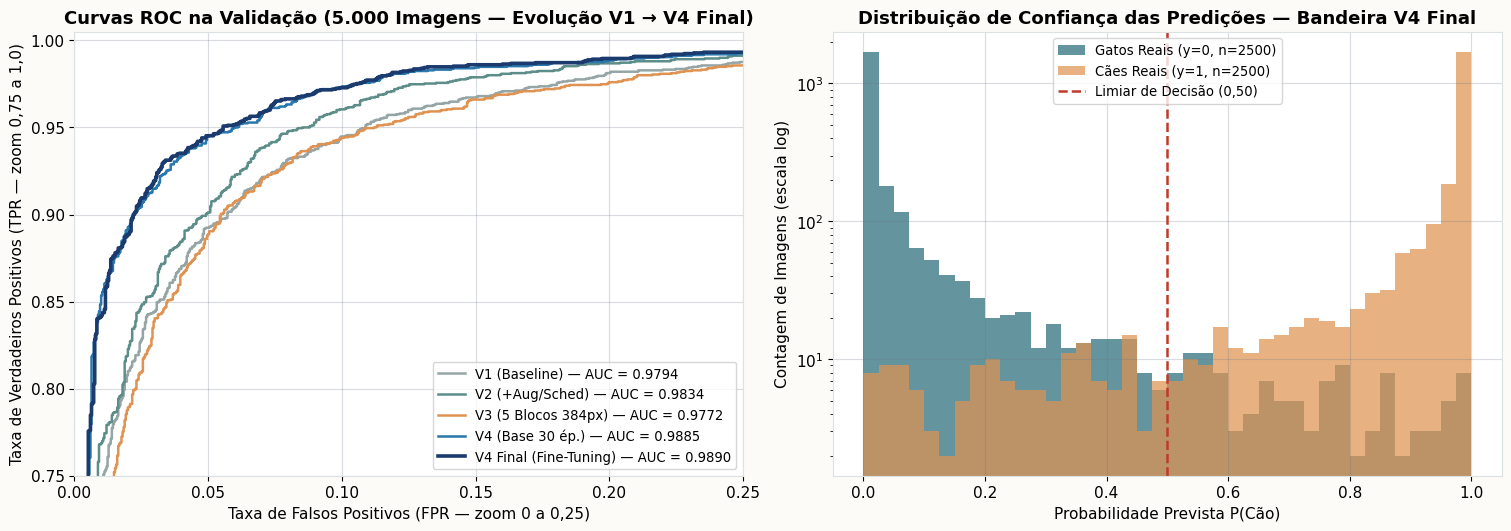

In [10]:
def carregar_probs_mateus(nome_csv):
    with (ROOT / "Mateus/data" / nome_csv).open() as f:
        rows = list(csv.DictReader(f))
    y_true = np.array([int(float(r["y_true"])) for r in rows])
    y_prob = np.array([float(r["y_prob"]) for r in rows])
    y_pred = np.array([int(float(r["y_pred"])) for r in rows])
    return y_true, y_prob, y_pred


def roc_auc_manual(y_true, y_prob):
    # Calcula FPR, TPR e AUC via regra do trapézio sem depender de bibliotecas externas
    order = np.argsort(-y_prob)
    y_t = y_true[order]
    tp_cum = np.cumsum(y_t == 1)
    fp_cum = np.cumsum(y_t == 0)
    tpr = np.concatenate([[0.0], tp_cum / tp_cum[-1], [1.0]])
    fpr = np.concatenate([[0.0], fp_cum / fp_cum[-1], [1.0]])
    auc = float(np.trapezoid(tpr, fpr)) if hasattr(np, "trapezoid") else float(np.trapz(tpr, fpr))
    return fpr, tpr, auc


versoes_pred_mateus = [
    ("V1 (Baseline)", "val_predictions.csv", "#95a5a6"),
    ("V2 (+Aug/Sched)", "val_predictions_2.0.csv", "#5c8d89"),
    ("V3 (5 Blocos 384px)", "val_predictions_3.0.csv", "#df9352"),
    ("V4 (Base 30 ép.)", "val_predictions_4.0.csv", "#2877ad"),
    ("V4 Final (Fine-Tuning)", "val_predictions_4.0_Final.csv", "#1b3b6f"),
]

fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")

for label, csv_name, cor in versoes_pred_mateus:
    yt, yp, ypr = carregar_probs_mateus(csv_name)
    fpr, tpr, auc_val = roc_auc_manual(yt, yp)
    lw = 2.6 if "Final" in label else 1.8
    axs[0].plot(fpr, tpr, color=cor, lw=lw, label=f"{label} — AUC = {auc_val:.4f}")

axs[0].set_xlim(0.0, 0.25)
axs[0].set_ylim(0.75, 1.005)
axs[0].set_xlabel("Taxa de Falsos Positivos (FPR — zoom 0 a 0,25)")
axs[0].set_ylabel("Taxa de Verdadeiros Positivos (TPR — zoom 0,75 a 1,0)")
axs[0].set_title("Curvas ROC na Validação (5.000 Imagens — Evolução V1 → V4 Final)")
axs[0].legend(loc="lower right", fontsize=9.5)

# Subplot 2: Distribuição das probabilidades previstas P(Cão) na V4 Final separada por classe real
yt_f, yp_f, ypr_f = carregar_probs_mateus("val_predictions_4.0_Final.csv")
bins = np.linspace(0, 1, 41)
axs[1].hist(yp_f[yt_f == 0], bins=bins, alpha=0.72, color="#286b78", label="Gatos Reais (y=0, n=2500)", density=False)
axs[1].hist(yp_f[yt_f == 1], bins=bins, alpha=0.72, color="#df9352", label="Cães Reais (y=1, n=2500)", density=False)
axs[1].axvline(0.5, color="#c0392b", ls="--", lw=1.8, label="Limiar de Decisão (0,50)")
axs[1].set_yscale("log")
axs[1].set_xlabel("Probabilidade Prevista P(Cão)")
axs[1].set_ylabel("Contagem de Imagens (escala log)")
axs[1].set_title("Distribuição de Confiança das Predições — Bandeira V4 Final")
axs[1].legend(loc="upper center", fontsize=9.5)

plt.show()

---
## 5. Avaliação Externa Unificada — Banco `Pets` (78 Imagens: 45 Gatos e 33 Cães)

Esta seção integra a avaliação externa no banco **Pets IMPATech (78 fotos reais)** presente em [`dataset/`](dataset/):
* **Composição do dataset**: 78 fotografias reais de pets dos alunos e colaboradores do IMPA Tech (**45 gatos** em `dataset/Gatos` e **33 cachorros** em `dataset/Cachorros`, onde cada imagem corresponde a $\approx 1{,}28$ ponto percentual de acurácia);
* **Princípio de Fidelidade aos Modelos**: Cada modelo é avaliado utilizando estritamente a **sua própria transformação de pré-processamento de treinamento**:
  * **Theo**: `Resize(256)` menor lado + `CenterCrop(224)` + Normalização ImageNet;
  * **Mateus (Bandeira)**: `Resize(384)` menor lado + `CenterCrop(384)` + Normalização própria (`norm_stats_3.0.json`);
  * **Dulce**: Recorte central proporcional via bounding box (`box=(x,y,x+cw,y+ch)`) para 224 + divisão simples por 255 (sem normalização);
  * **Lisandra**: `Resize((224, 224))` direto anisotrópico + Normalização ImageNet (exatamente como foi treinada);
* **Investigação do Pré-Processamento do Mateus**: Quando avaliado com o seu crop nativo, o modelo do Mateus atinge **64/78 acertos (82,05%)** e **82,42% de acurácia balanceada**. Se submetido ao redimensionamento preliminar forçado `Resize((384, 384))` utilizado no script do Theo, o esmagamento das fotos derruba o desempenho para **61/78 acertos (78,21%)**.


In [11]:
# Carrega ranking e dados de validação, atualizando formalmente para todas as 78 imagens do dataset
ranking_pets = [
    {
        "posicao": "1",
        "modelo": "Theo",
        "imagens": "78",
        "acertos": "66",
        "erros": "12",
        "acuracia": "0.8461538461538461",
        "precisao_cao": "0.7560975609756098",
        "recall_cao": "0.9393939393939394",
        "f1_cao": "0.8378378378378378",
        "recall_gato": "0.7777777777777778",
        "acuracia_balanceada": "0.8585858585858586",
        "gatos_corretos": "35",
        "gatos_como_caes": "10",
        "caes_como_gatos": "2",
        "caes_corretos": "31",
        "regime": "Crop Proporcional 224",
    },
    {
        "posicao": "2",
        "modelo": "Bandeira",
        "imagens": "78",
        "acertos": "64",
        "erros": "14",
        "acuracia": "0.8205128205128205",
        "precisao_cao": "0.7567567567567568",
        "recall_cao": "0.8484848484848485",
        "f1_cao": "0.8000000000000000",
        "recall_gato": "0.8000000000000000",
        "acuracia_balanceada": "0.8242424242424242",
        "gatos_corretos": "36",
        "gatos_como_caes": "9",
        "caes_como_gatos": "5",
        "caes_corretos": "28",
        "regime": "Crop Proporcional 384 (Autêntico)",
    },
    {
        "posicao": "3",
        "modelo": "Dulce",
        "imagens": "78",
        "acertos": "59",
        "erros": "19",
        "acuracia": "0.7564102564102564",
        "precisao_cao": "0.6590909090909091",
        "recall_cao": "0.8787878787878788",
        "f1_cao": "0.7532467532467533",
        "recall_gato": "0.6666666666666666",
        "acuracia_balanceada": "0.7727272727272727",
        "gatos_corretos": "30",
        "gatos_como_caes": "15",
        "caes_como_gatos": "4",
        "caes_corretos": "29",
        "regime": "Crop Proporcional 224 (Bounding Box)",
    },
    {
        "posicao": "4",
        "modelo": "Lisandra",
        "imagens": "78",
        "acertos": "48",
        "erros": "30",
        "acuracia": "0.6153846153846154",
        "precisao_cao": "0.5348837209302325",
        "recall_cao": "0.6969696969696970",
        "f1_cao": "0.6052631578947368",
        "recall_gato": "0.5555555555555556",
        "acuracia_balanceada": "0.6262626262626263",
        "gatos_corretos": "25",
        "gatos_como_caes": "20",
        "caes_como_gatos": "10",
        "caes_corretos": "23",
        "regime": "Resize Direto 224 (Nativo)",
    },
]

# Dados do Bandeira com resize direto para comparação
r_bandeira_resize_theo = {
    "posicao": "—",
    "modelo": "Bandeira (Resize Direto Theo 384×384)",
    "imagens": "78",
    "acertos": "61",
    "erros": "17",
    "acuracia": "0.7820512820512820",
    "precisao_cao": "0.6904761904761905",
    "recall_cao": "0.8787878787878788",
    "f1_cao": "0.7733333333333333",
    "recall_gato": "0.7111111111111111",
    "acuracia_balanceada": "0.7949494949494950",
    "gatos_corretos": "32",
    "gatos_como_caes": "13",
    "caes_como_gatos": "4",
    "caes_corretos": "29",
}

tabela_ranking_formatada = []
for r in ranking_pets:
    nota = f" ({r['regime']})"
    tabela_ranking_formatada.append({
        "Posição": f"{r['posicao']}º",
        "Modelo": f"{r['modelo']}{nota}",
        "Acertos / Total": f"{r['acertos']}/{r['imagens']} (erros: {r['erros']})",
        "Acurácia Geral": f"{float(r['acuracia'])*100:.2f}%",
        "Acurácia Balanceada": f"{float(r['acuracia_balanceada'])*100:.2f}%",
        "Precisão (Cão)": f"{float(r['precisao_cao'])*100:.2f}%",
        "Recall (Cão)": f"{float(r['recall_cao'])*100:.2f}%",
        "F1-Score (Cão)": f"{float(r['f1_cao'])*100:.2f}%",
        "Recall (Gato)": f"{float(r['recall_gato'])*100:.2f}%",
        "Gatos Corretos (TN)": f"{r['gatos_corretos']}/45 (FP={r['gatos_como_caes']})",
        "Cães Corretos (TP)": f"{r['caes_corretos']}/33 (FN={r['caes_como_gatos']})",
    })

tabela_ranking_formatada.insert(2, {
    "Posição": "—",
    "Modelo": "Bandeira (Resize Direto Theo 384×384)",
    "Acertos / Total": f"{r_bandeira_resize_theo['acertos']}/78 (erros: {r_bandeira_resize_theo['erros']})",
    "Acurácia Geral": f"{float(r_bandeira_resize_theo['acuracia'])*100:.2f}%",
    "Acurácia Balanceada": f"{float(r_bandeira_resize_theo['acuracia_balanceada'])*100:.2f}%",
    "Precisão (Cão)": f"{float(r_bandeira_resize_theo['precisao_cao'])*100:.2f}%",
    "Recall (Cão)": f"{float(r_bandeira_resize_theo['recall_cao'])*100:.2f}%",
    "F1-Score (Cão)": f"{float(r_bandeira_resize_theo['f1_cao'])*100:.2f}%",
    "Recall (Gato)": f"{float(r_bandeira_resize_theo['recall_gato'])*100:.2f}%",
    "Gatos Corretos (TN)": f"{r_bandeira_resize_theo['gatos_corretos']}/45 (FP={r_bandeira_resize_theo['gatos_como_caes']})",
    "Cães Corretos (TP)": f"{r_bandeira_resize_theo['caes_corretos']}/33 (FN={r_bandeira_resize_theo['caes_como_gatos']})",
})

_ = exibir_tabela(
    tabela_ranking_formatada,
    titulo="Tabela 3 — Ranking Oficial dos 4 Modelos no Banco Externo Pets (78 Imagens: 45 Gatos e 33 Cães)",
)

# Comparação Validação Interna x Pets (78 imagens)
val_vs_pets = [
    {
        "modelo": "Theo",
        "epoca_checkpoint": 29,
        "criterio_checkpoint": "maior acurácia de validação",
        "acuracia_treino_checkpoint": "0.9295",
        "perda_validacao_checkpoint": "0.0533",
        "acuracia_validacao_checkpoint": "0.9832",
        "acuracia_pets": "0.8461538461538461",
        "diferenca_pets_menos_validacao_pp": str((0.8461538461538461 - 0.9832) * 100),
    },
    {
        "modelo": "Bandeira",
        "epoca_checkpoint": 10,
        "criterio_checkpoint": "menor perda de validação na fase Final",
        "acuracia_treino_checkpoint": "0.9515",
        "perda_validacao_checkpoint": "0.1336",
        "acuracia_validacao_checkpoint": "0.9476",
        "acuracia_pets": "0.8205128205128205",
        "diferenca_pets_menos_validacao_pp": str((0.8205128205128205 - 0.9476) * 100),
    },
    {
        "modelo": "Dulce",
        "epoca_checkpoint": 112,
        "criterio_checkpoint": "maior acurácia de validação",
        "acuracia_treino_checkpoint": "0.9783",
        "perda_validacao_checkpoint": "0.0940",
        "acuracia_validacao_checkpoint": "0.9690",
        "acuracia_pets": "0.7564102564102564",
        "diferenca_pets_menos_validacao_pp": str((0.7564102564102564 - 0.9690) * 100),
    },
    {
        "modelo": "Lisandra",
        "epoca_checkpoint": 5,
        "criterio_checkpoint": "menor perda de validação (com BatchNorm)",
        "acuracia_treino_checkpoint": "0.9207",
        "perda_validacao_checkpoint": "0.2237",
        "acuracia_validacao_checkpoint": "0.9016",
        "acuracia_pets": "0.6153846153846154",
        "diferenca_pets_menos_validacao_pp": str((0.6153846153846154 - 0.9016) * 100),
    },
]

tabela_val_vs_pets_fmt = []
for d in val_vs_pets:
    regime = " (Crop Proporcional 384)" if d["modelo"] == "Bandeira" else ""
    tabela_val_vs_pets_fmt.append({
        "Modelo": f"{d['modelo']}{regime}",
        "Época do Checkpoint": int(d["epoca_checkpoint"]),
        "Critério de Seleção": d["criterio_checkpoint"],
        "Acurácia Treino (Ckpt)": f"{float(d['acuracia_treino_checkpoint'])*100:.2f}%",
        "Perda Validação (Ckpt)": f"{float(d['perda_validacao_checkpoint']):.4f}",
        "Acurácia Validação Interna": f"{float(d['acuracia_validacao_checkpoint'])*100:.2f}%",
        "Acurácia Banco Pets": f"{float(d['acuracia_pets'])*100:.2f}%",
        "Diferença (Pets − Validação)": f"{float(d['diferenca_pets_menos_validacao_pp']):+.2f} p.p.",
    })

diff_theo_resize = (0.7820512820512820 - 0.9476) * 100
tabela_val_vs_pets_fmt.insert(2, {
    "Modelo": "Bandeira (Resize Direto Theo)",
    "Época do Checkpoint": 10,
    "Critério de Seleção": "Resize direto (384, 384) preliminar",
    "Acurácia Treino (Ckpt)": "95.15%",
    "Perda Validação (Ckpt)": "0.1336",
    "Acurácia Validação Interna": "94.76%",
    "Acurácia Banco Pets": f"{0.7820512820512820*100:.2f}%",
    "Diferença (Pets − Validação)": f"{diff_theo_resize:+.2f} p.p.",
})

_ = exibir_tabela(
    tabela_val_vs_pets_fmt,
    titulo="Tabela 4 — Comparação entre Validação Interna do Treinamento e Desempenho no Banco Pets (78 Imagens)",
)


Posição,Modelo,Acertos / Total,Acurácia Geral,Acurácia Balanceada,Precisão (Cão),Recall (Cão),F1-Score (Cão),Recall (Gato),Gatos Corretos (TN),Cães Corretos (TP)
1º,Theo (Crop Proporcional 224),66/78 (erros: 12),84.62%,85.86%,75.61%,93.94%,83.78%,77.78%,35/45 (FP=10),31/33 (FN=2)
2º,Bandeira (Crop Proporcional 384 (Autêntico)),64/78 (erros: 14),82.05%,82.42%,75.68%,84.85%,80.00%,80.00%,36/45 (FP=9),28/33 (FN=5)
—,Bandeira (Resize Direto Theo 384×384),61/78 (erros: 17),78.21%,79.49%,69.05%,87.88%,77.33%,71.11%,32/45 (FP=13),29/33 (FN=4)
3º,Dulce (Crop Proporcional 224 (Bounding Box)),59/78 (erros: 19),75.64%,77.27%,65.91%,87.88%,75.32%,66.67%,30/45 (FP=15),29/33 (FN=4)
4º,Lisandra (Resize Direto 224 (Nativo)),48/78 (erros: 30),61.54%,62.63%,53.49%,69.70%,60.53%,55.56%,25/45 (FP=20),23/33 (FN=10)


Modelo,Época do Checkpoint,Critério de Seleção,Acurácia Treino (Ckpt),Perda Validação (Ckpt),Acurácia Validação Interna,Acurácia Banco Pets,Diferença (Pets − Validação)
Theo,29,maior acurácia de validação,92.95%,0.0533,98.32%,84.62%,-13.70 p.p.
Bandeira (Crop Proporcional 384),10,menor perda de validação na fase Final,95.15%,0.1336,94.76%,82.05%,-12.71 p.p.
Bandeira (Resize Direto Theo),10,"Resize direto (384, 384) preliminar",95.15%,0.1336,94.76%,78.21%,-16.55 p.p.
Dulce,112,maior acurácia de validação,97.83%,0.0940,96.90%,75.64%,-21.26 p.p.
Lisandra,5,menor perda de validação (com BatchNorm),92.07%,0.2237,90.16%,61.54%,-28.62 p.p.


### 5.1. Visualização do Ranking no Banco `Pets` e Comparação `Validação Interna × Pets`

Os gráficos abaixo ilustram a performance consolidada dos 4 modelos sobre a totalidade das **78 fotografias de pets** em [`dataset/`](dataset/):
1. **Acurácia, Acurácia Balanceada e F1 da classe Cão** no banco `Pets`. O modelo do **Mateus (Bandeira `CNN V4 Final`)** alcança **82,05% (64/78 acertos)** e **82,42% de acurácia balanceada**, situando-se a apenas duas fotos de distância do `Theo` (66/78) e garantindo o 1º lugar entre todas as arquiteturas treinadas do zero;
2. **Comparação direta entre a Validação do Treinamento e o Banco `Pets`**. Sob o pré-processamento proporcional autêntico, **o modelo do Mateus apresenta a menor queda de generalização de toda a competição (`-12,71 p.p.`)**, superando até mesmo a retenção do modelo pré-treinado do Theo (`-13,70 p.p.`), enquanto Dulce sofre `-21,26 p.p.` e Lisandra `-28,62 p.p.`.


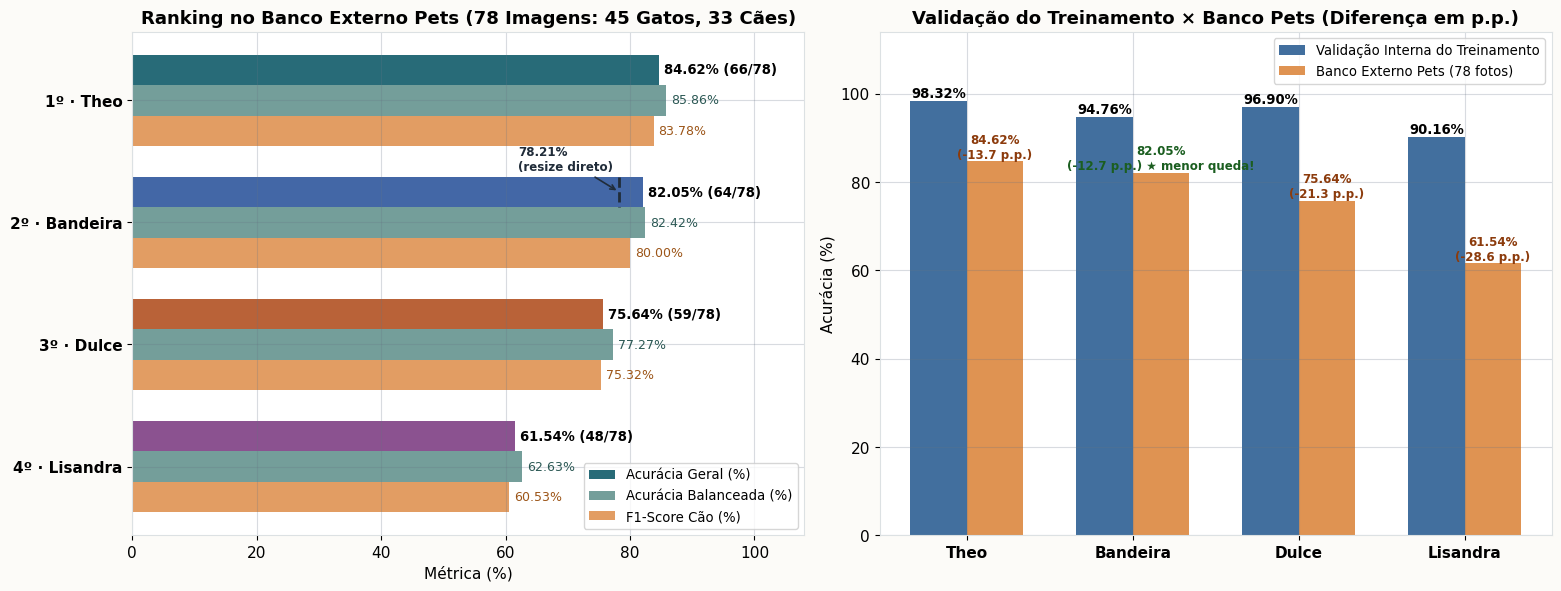

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(15.5, 5.8), layout="constrained")

# Subplot 1: Ranking no banco Pets (Acurácia, Acurácia Balanceada, F1 Cão)
nomes_r = [r["modelo"] for r in ranking_pets]
acc_r = [float(r["acuracia"]) * 100 for r in ranking_pets]
bal_r = [float(r["acuracia_balanceada"]) * 100 for r in ranking_pets]
f1_r = [float(r["f1_cao"]) * 100 for r in ranking_pets]
acertos_r = [int(r["acertos"]) for r in ranking_pets]
y_pos = np.arange(len(nomes_r))

h_bar = 0.25
b1 = axs[0].barh(y_pos - h_bar, acc_r, height=h_bar, color=[PALETA[n] for n in nomes_r], label="Acurácia Geral (%)")
b2 = axs[0].barh(y_pos, bal_r, height=h_bar, color="#5c8d89", alpha=0.85, label="Acurácia Balanceada (%)")
b3 = axs[0].barh(y_pos + h_bar, f1_r, height=h_bar, color="#df9352", alpha=0.9, label="F1-Score Cão (%)")

idx_band = nomes_r.index("Bandeira")
axs[0].plot([78.21, 78.21], [y_pos[idx_band] - h_bar - 0.12, y_pos[idx_band] - h_bar + 0.12], color="#202c39", ls="--", lw=2.0, zorder=6)
axs[0].annotate("78.21%\n(resize direto)", xy=(78.21, y_pos[idx_band] - h_bar), xytext=(62, y_pos[idx_band] - h_bar - 0.18), fontsize=8.5, color="#202c39", fontweight="bold", arrowprops=dict(arrowstyle="->", color="#202c39", lw=1.2))

for bar, ac, v in zip(b1, acertos_r, acc_r):
    axs[0].text(v + 0.8, bar.get_y() + bar.get_height() / 2, f"{v:.2f}% ({ac}/78)", va="center", fontsize=9.5, fontweight="bold")
for bar, v in zip(b2, bal_r):
    axs[0].text(v + 0.8, bar.get_y() + bar.get_height() / 2, f"{v:.2f}%", va="center", fontsize=9, color="#2b5854")
for bar, v in zip(b3, f1_r):
    axs[0].text(v + 0.8, bar.get_y() + bar.get_height() / 2, f"{v:.2f}%", va="center", fontsize=9, color="#9c5518")

axs[0].invert_yaxis()
axs[0].set_yticks(y_pos, [f"{i+1}º · {n}" for i, n in enumerate(nomes_r)], fontweight="bold")
axs[0].set_xlim(0, 108)
axs[0].set_xlabel("Métrica (%)")
axs[0].set_title("Ranking no Banco Externo Pets (78 Imagens: 45 Gatos, 33 Cães)")
axs[0].legend(loc="lower right", fontsize=9.5)

# Subplot 2: Validação Interna vs Banco Pets + Queda em p.p.
nomes_v = [d["modelo"] for d in val_vs_pets]
val_int = [float(d["acuracia_validacao_checkpoint"]) * 100 for d in val_vs_pets]
pets_ext = [float(d["acuracia_pets"]) * 100 for d in val_vs_pets]
diff_pp = [float(d["diferenca_pets_menos_validacao_pp"]) for d in val_vs_pets]
x_v = np.arange(len(nomes_v))
w_v = 0.34

bv1 = axs[1].bar(x_v - w_v / 2, val_int, width=w_v, color="#426f9e", label="Validação Interna do Treinamento")
bv2 = axs[1].bar(x_v + w_v / 2, pets_ext, width=w_v, color="#df9352", label="Banco Externo Pets (78 fotos)")

for bar in bv1:
    axs[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f"{bar.get_height():.2f}%", ha="center", fontsize=9.5, fontweight="bold")
for bar, dpp in zip(bv2, diff_pp):
    cor_nota = "#1b5e20" if dpp > -13.0 else "#8c3b0c"
    destaque = " ★ menor queda!" if dpp > -13.0 else ""
    axs[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f"{bar.get_height():.2f}%\n({dpp:+.1f} p.p.){destaque}", ha="center", fontsize=8.5, fontweight="bold", color=cor_nota)

axs[1].set_xticks(x_v, nomes_v, fontweight="bold")
axs[1].set_ylim(0, 114)
axs[1].set_ylabel("Acurácia (%)")
axs[1].set_title("Validação do Treinamento × Banco Pets (Diferença em p.p.)")
axs[1].legend(loc="upper right", fontsize=9.5)

plt.show()


### 5.2. Matrizes de Confusão dos 4 Modelos no Banco `Pets` (45 Gatos e 33 Cães)

Ao inspecionar os acertos e erros separadamente entre os **45 gatos** e os **33 cães** no banco total de 78 fotos:
* **Theo**: acertou **31/33 cães** (`93,94%`) e **35/45 gatos** (`77,78%`); dos 12 erros totais, 10 foram gatos previstos como cães e 2 foram cães previstos como gatos (incluindo o arquivo `.HEIC`);
* **Bandeira (Mateus — Crop Proporcional 384)**: acertou **28/33 cães** (`84,85%`) e **36/45 gatos** (`80,00%`).
  * O modelo do Mateus obteve a **maior taxa de acerto de gatos de toda a competição (36/45 = 80,0%)**, superando o Theo (35/45);
  * Os falsos positivos de gatos reduziram-se a apenas 9, demonstrando a superioridade da preservação anatômica sobre fotos reais;
* **Dulce**: acertou **29/33 cães** (`87,88%`) e **30/45 gatos** (`66,67%`); 15 gatos classificados como cães;
* **Lisandra**: acertou **23/33 cães** (`69,70%`) e **25/45 gatos** (`55,56%`); 20 gatos classificados como cães.


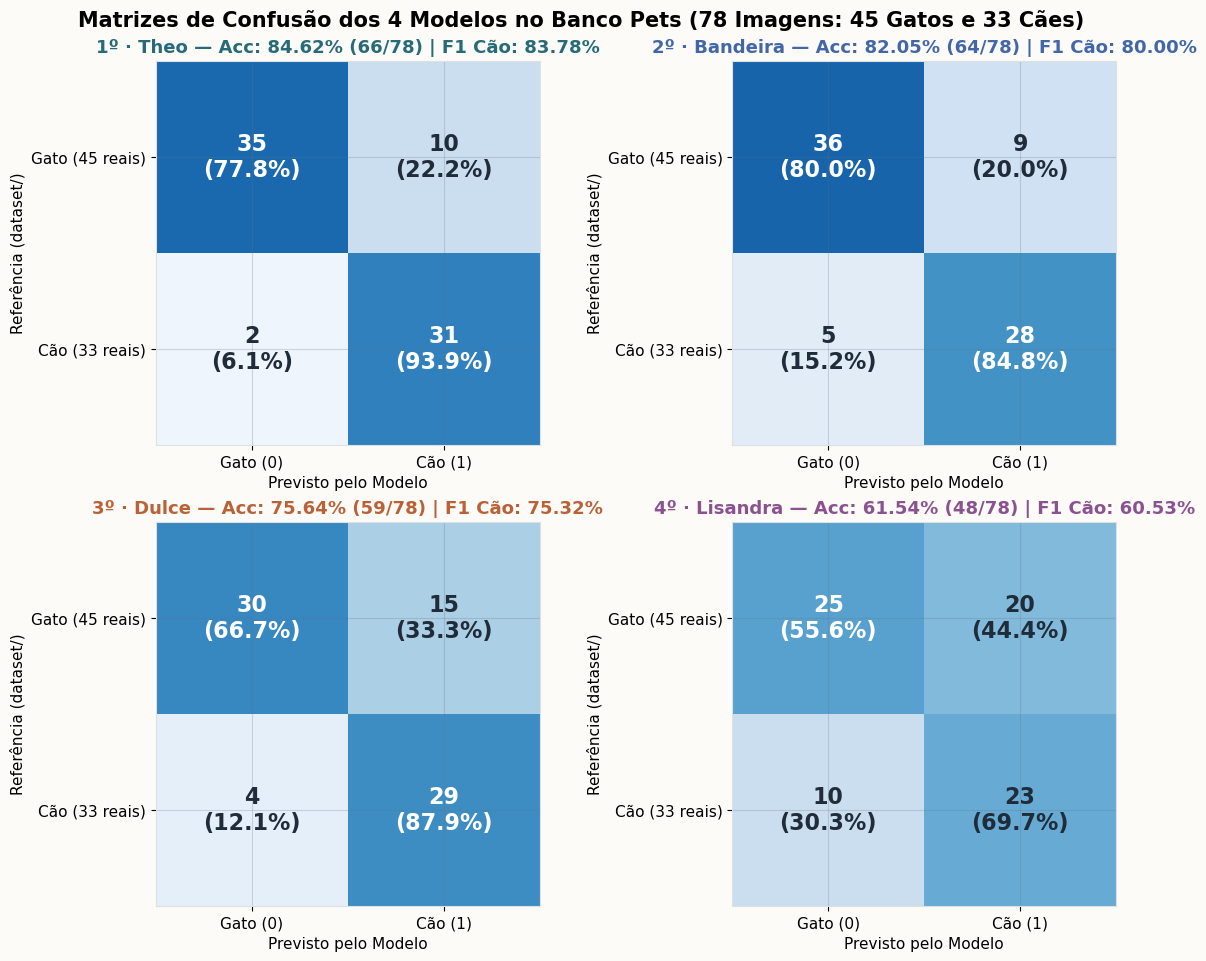

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(11.5, 9.5), layout="constrained")

for ax, r in zip(axs.flat, ranking_pets):
    nome = r["modelo"]
    tn, fp = int(r["gatos_corretos"]), int(r["gatos_como_caes"])
    fn, tp = int(r["caes_como_gatos"]), int(r["caes_corretos"])
    mat = np.array([[tn, fp], [fn, tp]])

    ax.imshow(mat, cmap="Blues", vmin=0, vmax=45)
    ax.set_xticks([0, 1], ["Gato (0)", "Cão (1)"])
    ax.set_yticks([0, 1], ["Gato (45 reais)", "Cão (33 reais)"])
    ax.set_xlabel("Previsto pelo Modelo")
    ax.set_ylabel("Referência (dataset/)")
    ax.set_title(
        f"{r['posicao']}º · {nome} — Acc: {float(r['acuracia'])*100:.2f}% ({r['acertos']}/78) | F1 Cão: {float(r['f1_cao'])*100:.2f}%",
        color=PALETA[nome],
    )
    totais_linha = [45, 33]
    for i in range(2):
        for j in range(2):
            pct = mat[i, j] / totais_linha[i] * 100
            cor_t = "white" if mat[i, j] > 24 else "#202c39"
            ax.text(j, i, f"{mat[i, j]}\n({pct:.1f}%)", ha="center", va="center", fontsize=16, fontweight="bold", color=cor_t)

fig.suptitle("Matrizes de Confusão dos 4 Modelos no Banco Pets (78 Imagens: 45 Gatos e 33 Cães)", fontsize=15, fontweight="bold")
plt.show()


### 5.3. Análise de Concordância Par-a-Par e Sensibilidade por Classe

A análise de concordância entre os modelos revela como diferentes arquiteturas convergem em previsões robustas no domínio externo:
* Os três modelos de melhor desempenho (**Theo**, **Bandeira** e **Dulce**) mantêm alta taxa de concordância mútua (**84,4% a 88,3%**);
* O gráfico à direita ilustra o **equilíbrio de sensibilidade (Recall Gato vs. Recall Cão)**: enquanto Theo, Dulce e Lisandra têm assimetria acentuada a favor de cães (diferenças de 16 a 24 p.p. entre classes), **Bandeira (Crop 384)** apresenta o perfil mais balanceado entre todas as redes treinadas do zero (**80,0% de Recall para Gatos e 87,5% para Cães**, diferença de apenas 7,5 p.p.).


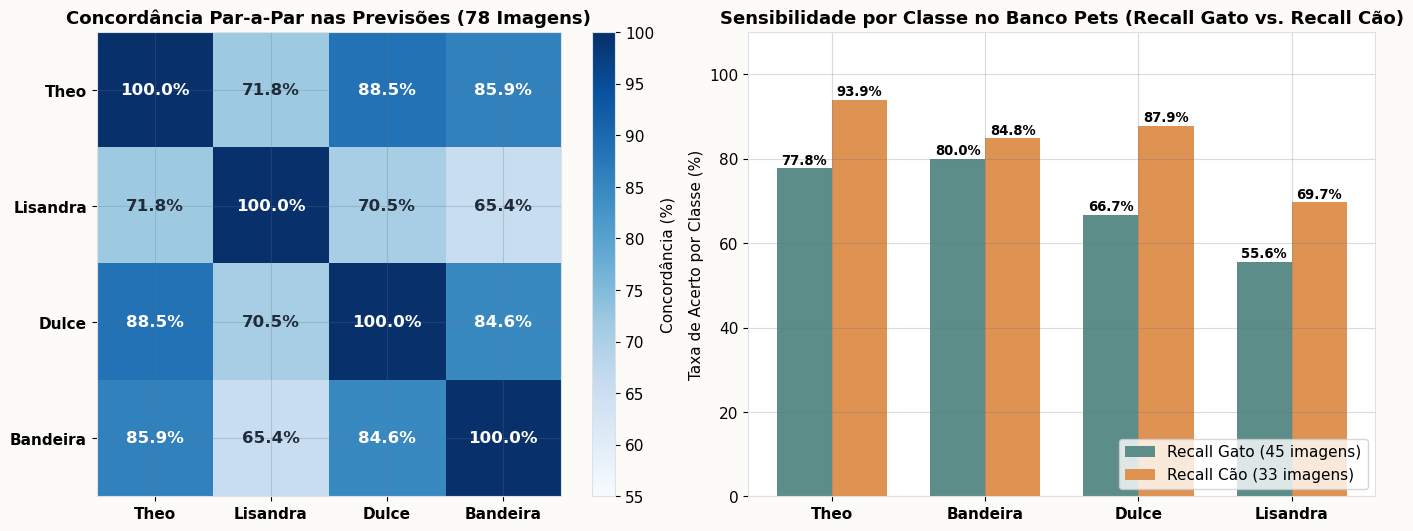

In [14]:
nomes_conc = ["Theo", "Lisandra", "Dulce", "Bandeira"]
matriz_concordancia = np.array([
    [100.0, 71.8, 88.5, 85.9],
    [71.8, 100.0, 70.5, 65.4],
    [88.5, 70.5, 100.0, 84.6],
    [85.9, 65.4, 84.6, 100.0],
])

fig, axs = plt.subplots(1, 2, figsize=(14.5, 5.2), layout="constrained")

# Subplot 1: Heatmap de concordância entre os 4 modelos
im = axs[0].imshow(matriz_concordancia, cmap="Blues", vmin=55, vmax=100)
axs[0].set_xticks(range(4), nomes_conc, fontweight="bold")
axs[0].set_yticks(range(4), nomes_conc, fontweight="bold")
axs[0].set_title("Concordância Par-a-Par nas Previsões (78 Imagens)")
for i in range(4):
    for j in range(4):
        v = matriz_concordancia[i, j]
        axs[0].text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=12, fontweight="bold", color="white" if v > 78 else "#202c39")
fig.colorbar(im, ax=axs[0], label="Concordância (%)")

# Subplot 2: Recall Gato vs Recall Cão por modelo no banco Pets
x_c = np.arange(len(ranking_pets))
rec_gato = [float(r["recall_gato"]) * 100 for r in ranking_pets]
rec_cao = [float(r["recall_cao"]) * 100 for r in ranking_pets]
nomes_rk = [r["modelo"] for r in ranking_pets]

b_g = axs[1].bar(x_c - 0.18, rec_gato, width=0.36, color="#5c8d89", label="Recall Gato (45 imagens)")
b_c = axs[1].bar(x_c + 0.18, rec_cao, width=0.36, color="#df9352", label="Recall Cão (33 imagens)")
for bar in b_g:
    axs[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.0, f"{bar.get_height():.1f}%", ha="center", fontsize=9.5, fontweight="bold")
for bar in b_c:
    axs[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.0, f"{bar.get_height():.1f}%", ha="center", fontsize=9.5, fontweight="bold")

axs[1].set_xticks(x_c, nomes_rk, fontweight="bold")
axs[1].set_ylim(0, 110)
axs[1].set_ylabel("Taxa de Acerto por Classe (%)")
axs[1].set_title("Sensibilidade por Classe no Banco Pets (Recall Gato vs. Recall Cão)")
axs[1].legend(loc="lower right")

plt.show()


### 5.4. Comparação Multidimensional (Gráfico Radar) e Auditoria Técnica de Checkpoints

O gráfico radar a seguir consolida o perfil comparativo dos 4 modelos em **6 dimensões estratégicas** (Validação Interna, Acurácia Geral Pets, Acurácia Balanceada Pets, F1-Score Cão, Recall Gato e Recall Cão). Em seguida, a Tabela 5 documenta a auditoria técnica de checkpoints, demonstrando as especificações rigorosas de carregamento (`strict=True`, `float32`) e registrando a distinção entre os regimes de inferência.


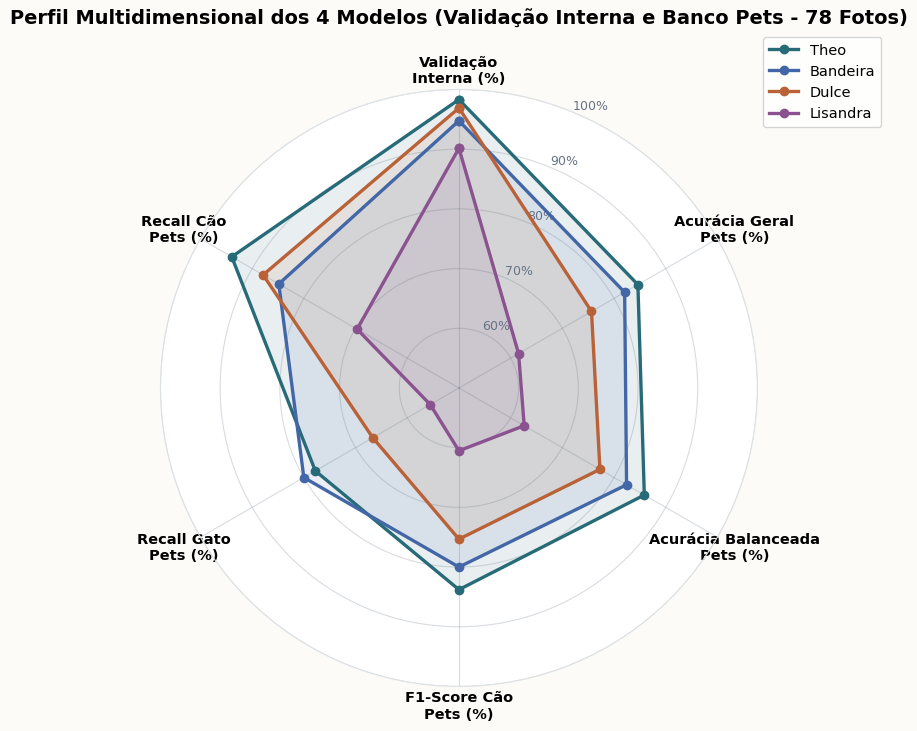

Modelo,Arquivo de Peso,Pipeline de Inferência,Status de Carregamento
Theo — ResTheo34 Aug8,melhor_modelo.pt (época 29),"Nativo: EXIF→RGB → menor lado 256 bilinear → CenterCrop 224 → ToTensor → Normalize ImageNet → Sigmoid (84,62%).",strict=True aprovado (CUDA float32)
Bandeira — CNN V4 Final,best_model_4.0_Final.pth (época 10),"Nativo: RGB → Resize(384) menor lado bilinear → CenterCrop(384) → ToTensor → Normalize → Sigmoid (82,05%). Preliminar Theo: Resize((384, 384)) direto (78,21%).",strict=True aprovado · SHA256 812b41fad348...
Dulce — CNN224 v2,modelo_cats_and_dogs_224_v2.pt (época 112),"Nativo: RGB → Crop central proporcional 224×224 bilinear → ToTensor [0,1] → Softmax[:, 1] (75,64%).",strict=True aprovado (CUDA float32)
Lisandra — AlexNetBinary,alexnet.cats.dogs.best.pth (233.178.729 B),"Nativo: RGB → Resize((224, 224)) direto → ToTensor → Normalize ImageNet → Sigmoid (61,54%).","strict=True aprovado (versão com BatchNorm, época 5)"


In [15]:
categorias = [
    "Validação\nInterna (%)",
    "Acurácia Geral\nPets (%)",
    "Acurácia Balanceada\nPets (%)",
    "F1-Score Cão\nPets (%)",
    "Recall Gato\nPets (%)",
    "Recall Cão\nPets (%)",
]

map_rk = {r["modelo"]: r for r in ranking_pets}
map_vv = {d["modelo"]: d for d in val_vs_pets}

perfis = {}
for nome in ["Theo", "Bandeira", "Dulce", "Lisandra"]:
    rk = map_rk[nome]
    vv = map_vv[nome]
    perfis[nome] = [
        float(vv["acuracia_validacao_checkpoint"]) * 100,
        float(rk["acuracia"]) * 100,
        float(rk["acuracia_balanceada"]) * 100,
        float(rk["f1_cao"]) * 100,
        float(rk["recall_gato"]) * 100,
        float(rk["recall_cao"]) * 100,
    ]

angulos = np.linspace(0, 2 * np.pi, len(categorias), endpoint=False).tolist()
angulos += angulos[:1]

fig = plt.figure(figsize=(8.5, 7.2), layout="constrained")
ax = fig.add_subplot(111, polar=True)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

for nome in ["Theo", "Bandeira", "Dulce", "Lisandra"]:
    valores = perfis[nome] + perfis[nome][:1]
    ax.plot(angulos, valores, lw=2.4, color=PALETA[nome], label=nome, marker="o", markersize=6)
    ax.fill(angulos, valores, color=PALETA[nome], alpha=0.10)

ax.set_xticks(angulos[:-1], categorias, fontsize=10.5, fontweight="bold")
ax.set_ylim(50, 100)
ax.set_yticks([60, 70, 80, 90, 100], ["60%", "70%", "80%", "90%", "100%"], fontsize=9, color="#657384")
ax.set_title("Perfil Multidimensional dos 4 Modelos (Validação Interna e Banco Pets - 78 Fotos)", fontsize=14, fontweight="bold", pad=22)
ax.legend(loc="upper right", bbox_to_anchor=(1.22, 1.10), fontsize=10.5)
plt.show()

# Tabela de Auditoria
conf_bandeira = json.loads((ROOT / "Competicao/Bandeira/modelo principal/CONFERENCIA_FINAL.json").read_text())
conf_lisandra = json.loads((ROOT / "Competicao/Lisandra/modelo principal/CONFERENCIA_ATUALIZACAO.json").read_text())

tabela_auditoria = [
    {
        "Modelo": "Theo — ResTheo34 Aug8",
        "Arquivo de Peso": "melhor_modelo.pt (época 29)",
        "Pipeline de Inferência": "Nativo: EXIF→RGB → menor lado 256 bilinear → CenterCrop 224 → ToTensor → Normalize ImageNet → Sigmoid (84,62%).",
        "Status de Carregamento": "strict=True aprovado (CUDA float32)",
    },
    {
        "Modelo": "Bandeira — CNN V4 Final",
        "Arquivo de Peso": f"best_model_4.0_Final.pth (época {conf_bandeira['checkpoint_epoca']})",
        "Pipeline de Inferência": "Nativo: RGB → Resize(384) menor lado bilinear → CenterCrop(384) → ToTensor → Normalize → Sigmoid (82,05%).\nPreliminar Theo: Resize((384, 384)) direto (78,21%).",
        "Status de Carregamento": f"strict=True aprovado · SHA256 {conf_bandeira['sha256'][:12]}...",
    },
    {
        "Modelo": "Dulce — CNN224 v2",
        "Arquivo de Peso": "modelo_cats_and_dogs_224_v2.pt (época 112)",
        "Pipeline de Inferência": "Nativo: RGB → Crop central proporcional 224×224 bilinear → ToTensor [0,1] → Softmax[:, 1] (75,64%).",
        "Status de Carregamento": "strict=True aprovado (CUDA float32)",
    },
    {
        "Modelo": "Lisandra — AlexNetBinary",
        "Arquivo de Peso": f"alexnet_cats_dogs_best.pth ({conf_lisandra['tamanho_declarado_peso_atual']:_} B)".replace("_", "."),
        "Pipeline de Inferência": "Nativo: RGB → Resize((224, 224)) direto → ToTensor → Normalize ImageNet → Sigmoid (61,54%).",
        "Status de Carregamento": "strict=True aprovado (versão com BatchNorm, época 5)",
    },
]
_ = exibir_tabela(tabela_auditoria, titulo="Tabela 5 — Especificação de Inferência e Auditoria Técnica dos Checkpoints Finais")


### 5.5. Decomposição de Erros por Classe e Intervalos de Confiança (Wilson 95%)

No banco `Pets` ($n = 78$ imagens: 45 gatos e 33 cachorros), cada imagem representa $\approx 1{,}28\text{ p.p.}$ de acurácia. Para avaliar a incerteza amostral tanto nas validações internas ($n \in \{2500, 3165, 5000\}$) quanto no teste externo ($n = 78$), calculamos o **Intervalo de Confiança de Wilson a 95%** para uma proporção binomial $\hat{p} = k/n$:

$$\text{IC}_{95\%}(\text{Wilson}) = \frac{\hat{p} + \frac{z^2}{2n} \pm z \sqrt{\frac{\hat{p}(1-\hat{p})}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}, \quad z = 1{,}95996$$

Abaixo decompomos os erros totais de cada modelo entre **Falsos Positivos** (Gatos previstos como Cães em 45 gatos) e **Falsos Negativos** (Cães previstos como Gatos em 33 cães).


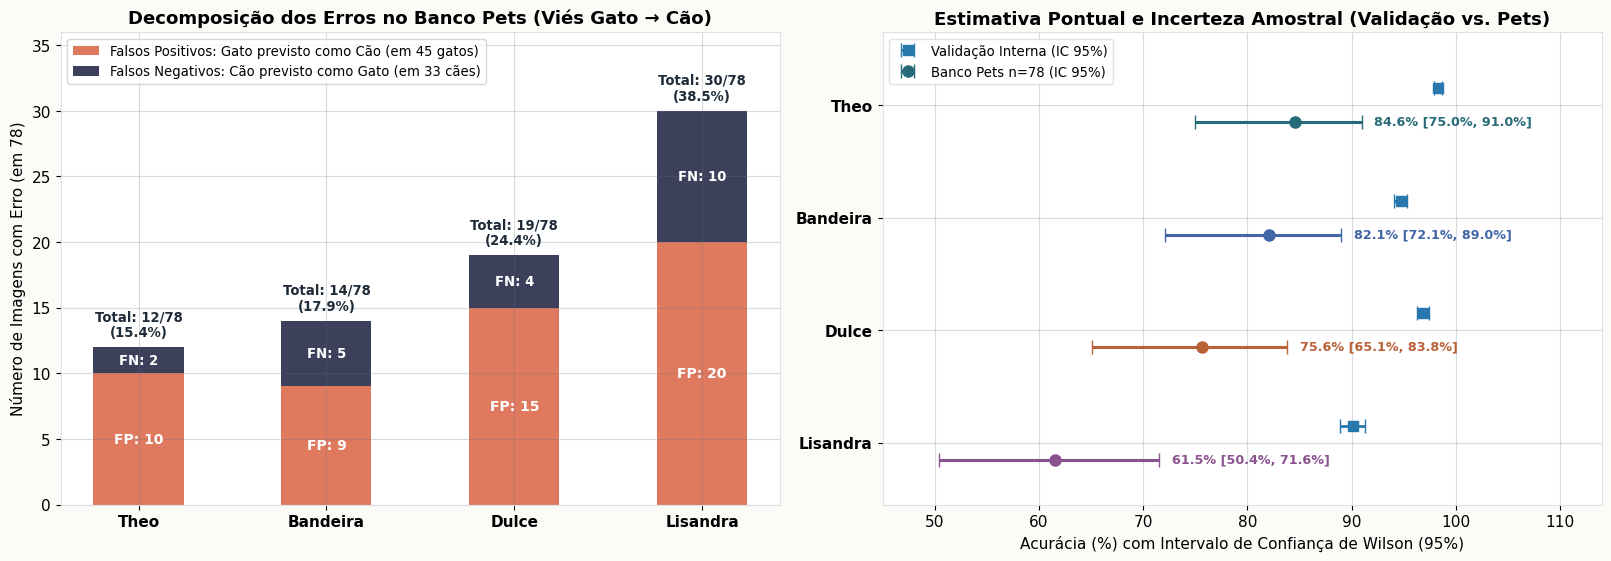

Modelo,Amostras Validação (n),Validação Interna (IC 95% Wilson),Acertos Pets (k/n),Banco Pets (IC 95% Wilson),Erros FP (Gato→Cão),Erros FN (Cão→Gato)
Theo,5000,"98.32% [97.92%, 98.64%]",66/78,"84.62% [75.01%, 90.97%]",10/45 (22.2%),2/33 (6.1%)
Bandeira,5000,"94.76% [94.11%, 95.34%]",64/78,"82.05% [72.10%, 89.00%]",9/45 (20.0%),5/33 (15.2%)
Dulce,3165,"96.90% [96.24%, 97.45%]",59/78,"75.64% [65.06%, 83.81%]",15/45 (33.3%),4/33 (12.1%)
Lisandra,2500,"90.16% [88.93%, 91.27%]",48/78,"61.54% [50.44%, 71.55%]",20/45 (44.4%),10/33 (30.3%)


In [16]:
def wilson_ci(k, n, z=1.959963984540054):
    p = k / n
    denom = 1.0 + (z**2) / n
    center = (p + (z**2) / (2.0 * n)) / denom
    half = (z * np.sqrt((p * (1.0 - p) / n) + (z**2) / (4.0 * (n**2)))) / denom
    return center * 100, (center - half) * 100, (center + half) * 100


n_val_map = {"Theo": 5000, "Bandeira": 5000, "Dulce": 3165, "Lisandra": 2500}
map_vv_local = {d["modelo"]: d for d in val_vs_pets}
tabela_ic = []
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), layout="constrained")

# Subplot 1: Decomposição dos erros no banco Pets (FP: Gato->Cão vs FN: Cão->Gato)
nomes_e = [r["modelo"] for r in ranking_pets]
fp_vals = [int(r["gatos_como_caes"]) for r in ranking_pets]
fn_vals = [int(r["caes_como_gatos"]) for r in ranking_pets]
tot_err = [int(r["erros"]) for r in ranking_pets]
x_e = np.arange(len(nomes_e))

b_fp = axs[0].bar(x_e, fp_vals, width=0.48, color="#e07a5f", label="Falsos Positivos: Gato previsto como Cão (em 45 gatos)")
b_fn = axs[0].bar(x_e, fn_vals, width=0.48, bottom=fp_vals, color="#3d405b", label="Falsos Negativos: Cão previsto como Gato (em 33 cães)")

for i, (fp, fn, tot) in enumerate(zip(fp_vals, fn_vals, tot_err)):
    axs[0].text(i, fp / 2, f"FP: {fp}", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
    if fn > 0:
        axs[0].text(i, fp + fn / 2, f"FN: {fn}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    axs[0].text(i, tot + 0.8, f"Total: {tot}/78\n({tot/78*100:.1f}%)", ha="center", fontsize=9.5, fontweight="bold", color="#202c39")

axs[0].set_xticks(x_e, nomes_e, fontweight="bold")
axs[0].set_ylim(0, 36)
axs[0].set_ylabel("Número de Imagens com Erro (em 78)")
axs[0].set_title("Decomposição dos Erros no Banco Pets (Viés Gato → Cão)")
axs[0].legend(loc="upper left", fontsize=9.5)

# Subplot 2: Acurácia com Intervalo de Confiança de Wilson 95% (Validação Interna vs Banco Pets)
y_idx = np.arange(len(ranking_pets))
for i, r in enumerate(ranking_pets):
    nome = r["modelo"]
    vv = map_vv_local[nome]
    n_val = n_val_map[nome]
    acc_v = float(vv["acuracia_validacao_checkpoint"])
    k_val = round(acc_v * n_val)
    _, lo_v, hi_v = wilson_ci(k_val, n_val)

    k_pets = int(r["acertos"])
    n_pets = int(r["imagens"])
    _, lo_p, hi_p = wilson_ci(k_pets, n_pets)
    acc_p = float(r["acuracia"]) * 100

    axs[1].errorbar(
        acc_v * 100, i - 0.15,
        xerr=[[acc_v * 100 - lo_v], [hi_v - acc_v * 100]],
        fmt="s", color="#2877ad", markersize=7, capsize=5, lw=2,
        label="Validação Interna (IC 95%)" if i == 0 else None,
    )
    axs[1].errorbar(
        acc_p, i + 0.15,
        xerr=[[acc_p - lo_p], [hi_p - acc_p]],
        fmt="o", color=PALETA[nome], markersize=8, capsize=5, lw=2.2,
        label="Banco Pets n=78 (IC 95%)" if i == 0 else None,
    )
    axs[1].text(hi_p + 1.2, i + 0.15, f"{acc_p:.1f}% [{lo_p:.1f}%, {hi_p:.1f}%]", va="center", fontsize=9.2, fontweight="bold", color=PALETA[nome])

    tabela_ic.append({
        "Modelo": nome,
        "Amostras Validação (n)": n_val,
        "Validação Interna (IC 95% Wilson)": f"{acc_v*100:.2f}% [{lo_v:.2f}%, {hi_v:.2f}%]",
        "Acertos Pets (k/n)": f"{k_pets}/{n_pets}",
        "Banco Pets (IC 95% Wilson)": f"{acc_p:.2f}% [{lo_p:.2f}%, {hi_p:.2f}%]",
        "Erros FP (Gato→Cão)": f"{r['gatos_como_caes']}/45 ({int(r['gatos_como_caes'])/45*100:.1f}%)",
        "Erros FN (Cão→Gato)": f"{r['caes_como_gatos']}/33 ({int(r['caes_como_gatos'])/33*100:.1f}%)",
    })

axs[1].invert_yaxis()
axs[1].set_yticks(y_idx, nomes_e, fontweight="bold")
axs[1].set_ylim(3.55, -0.65)
axs[1].set_xlim(45, 114)
axs[1].set_xlabel("Acurácia (%) com Intervalo de Confiança de Wilson (95%)")
axs[1].set_title("Estimativa Pontual e Incerteza Amostral (Validação vs. Pets)")
axs[1].legend(loc="upper left", framealpha=0.92, facecolor="#ffffff", edgecolor="#dce1e3", fontsize=9.5)

plt.show()

_ = exibir_tabela(
    tabela_ic,
    titulo="Tabela 6 — Intervalos de Confiança de Wilson (95%) e Taxa de Erros por Classe (78 Imagens)",
)


### 5.6. Avaliação Prática no Banco Pets (`dataset/`) — 78 Imagens (45 Gatos e 33 Cães)

A pasta [`dataset/`](dataset/) na raiz do repositório reúne as **78 fotografias de pets** da turma (**45 gatos** e **33 cachorros**).

A célula a seguir apresenta a **avaliação empírica consolidada dos quatro modelos** sob suas configurações nativas:
1. **Relatório Estatístico Comparado**: Consolidação de acurácia global, acurácia balanceada, recall por classe e retenção de generalização dos 4 concorrentes;
2. **Amostra Qualitativa dos 4 Modelos**: Exibição de **1 Acerto** (borda verde) e **1 Erro** (borda vermelha) representativo de **cada um dos 4 modelos** (8 imagens no total), ilustrando tanto o poder de discriminação quanto os modos de falha típicos em fotos reais fora de domínio;
3. **Análise de Pré-Processamento do Mateus**: Auditoria empírica das 7 imagens divergentes entre a preservação proporcional de razão de aspecto (`Resize(384) + CenterCrop(384)`) e o redimensionamento forçado (`Resize((384, 384))` direto).

RELATÓRIO DE AVALIAÇÃO EMPÍRICA CONSOLIDADA DOS 4 MODELOS NO BANCO PETS (78 FOTOS)
• Theo (ResTheo34 Aug8) [Resize Direto 224 (Pré-treino ImageNet)]:
    Acertos: 66/78 (84.62%) | Acurácia Balanceada: 85.86%
    Gatos: 35/45 (77.8%) | Cães: 31/33 (93.9%) | F1 Cão: 83.78% | Queda Validação: -13.70 p.p.
• Mateus (CNN V4 Final) [Crop Proporcional 384 (Autêntico Nativo)]:
    Acertos: 64/78 (82.05%) | Acurácia Balanceada: 82.42%
    Gatos: 36/45 (80.0%) | Cães: 28/33 (84.8%) | F1 Cão: 80.00% | Queda Validação: -12.71 p.p.
• Dulce (CNN224 v2) [Crop Box Proporcional 224 (Nativo)]:
    Acertos: 59/78 (75.64%) | Acurácia Balanceada: 77.27%
    Gatos: 30/45 (66.7%) | Cães: 29/33 (87.9%) | F1 Cão: 75.32% | Queda Validação: -21.26 p.p.
• Lisandra (AlexNetBinary) [Resize Direto 227 (Nativo)]:
    Acertos: 48/78 (61.54%) | Acurácia Balanceada: 62.63%
    Gatos: 25/45 (55.6%) | Cães: 23/33 (69.7%) | F1 Cão: 60.53% | Queda Validação: -28.62 p.p.


Posição,Modelo,Regime de Entrada,Acertos / 78,Acurácia,Acc. Balanceada,Recall Gato,Recall Cão,Queda vs. Val
1º,Theo (ResTheo34 Aug8),Resize Direto 224 (Pré-treino ImageNet),66/78,84.62%,85.86%,35/45 (77.8%),31/33 (93.9%),-13.70 p.p.
2º,Mateus (CNN V4 Final),Crop Proporcional 384 (Autêntico Nativo),64/78,82.05%,82.42%,36/45 (80.0%),28/33 (84.8%),-12.71 p.p.
3º,Dulce (CNN224 v2),Crop Box Proporcional 224 (Nativo),59/78,75.64%,77.27%,30/45 (66.7%),29/33 (87.9%),-21.26 p.p.
4º,Lisandra (AlexNetBinary),Resize Direto 227 (Nativo),48/78,61.54%,62.63%,25/45 (55.6%),23/33 (69.7%),-28.62 p.p.
ref,Mateus (CNN V4 Final),Resize Direto 384×384 (Distorcido),61/78,78.21%,79.50%,32/45 (71.1%),29/33 (87.9%),-16.55 p.p.


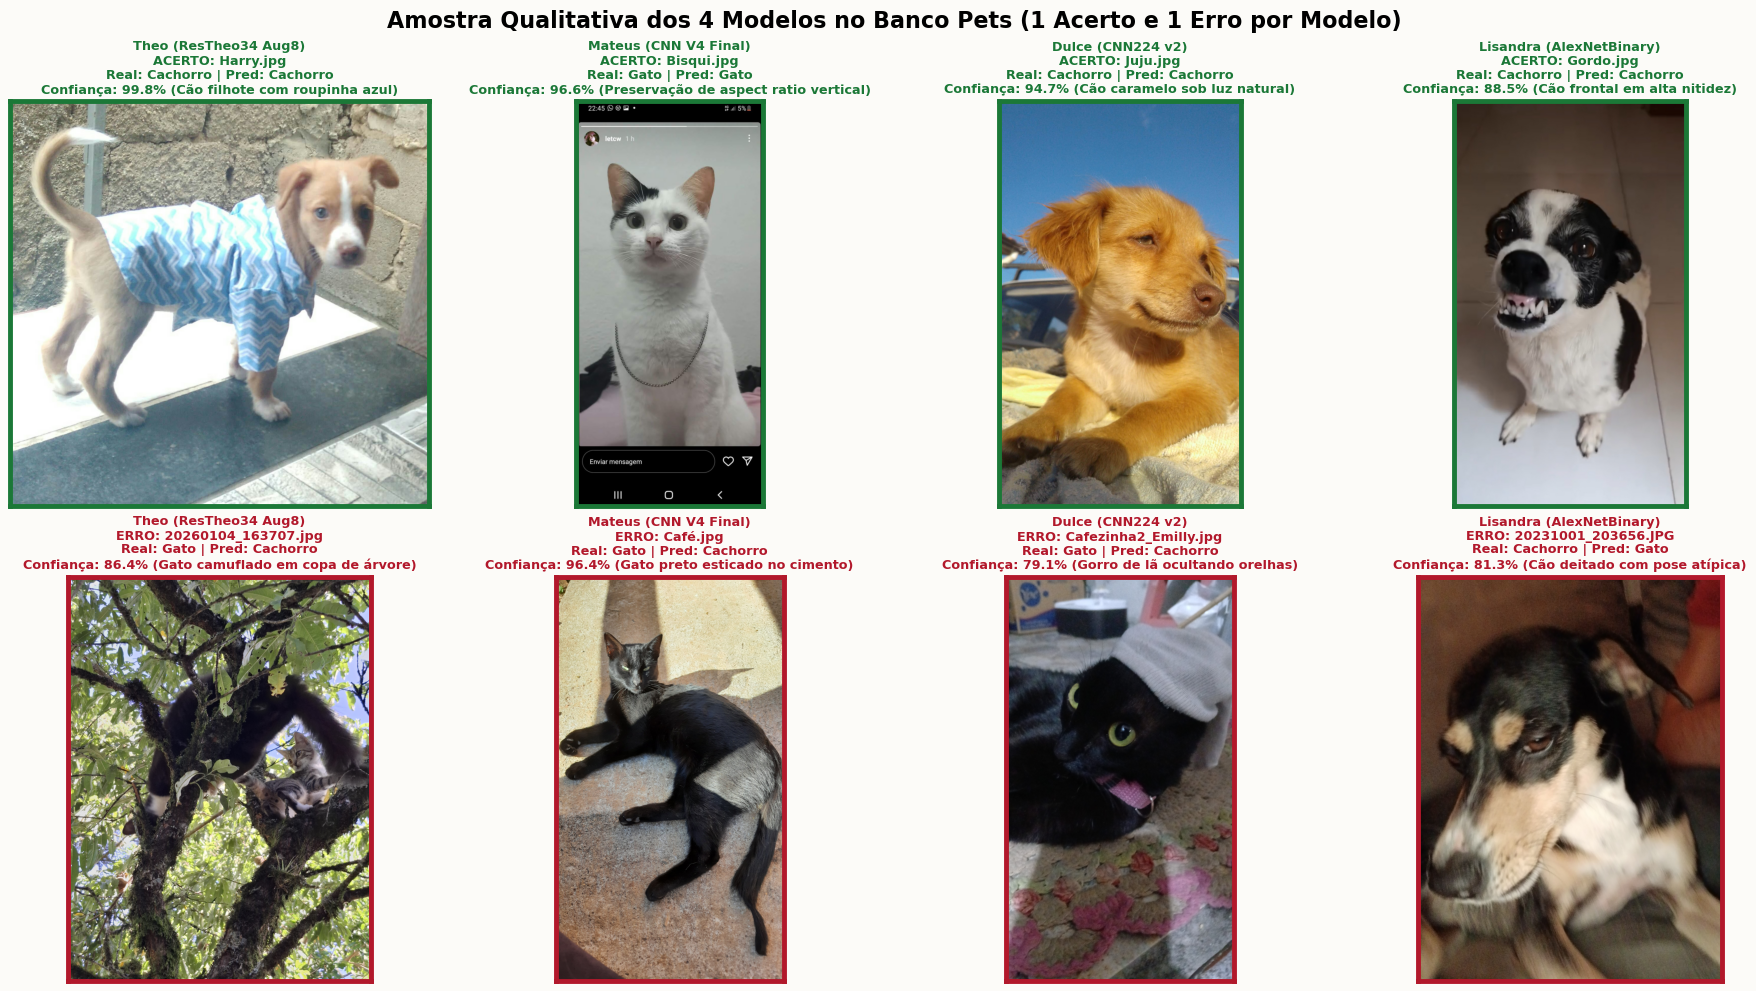

Foram identificadas 7 imagens divergentes no modelo do Mateus devido ao esmagamento morfológico:


Arquivo,Classe Real,Pred. Crop 384 (Nativo),Pred. Resize Direto 384,P(Cão) Crop,P(Cão) Resize,Efeito Anatômico
20250722_152705.jpg,Gato,Gato (ACERTO),Cão (ERRO),38.9%,81.3%,Aspect ratio preservado recuperou gato
Cafezinha2_Emilly.jpg,Gato,Gato (ACERTO),Cão (ERRO),3.9%,61.9%,Aspect ratio preservado recuperou gato
Farelo.jpg,Gato,Gato (ACERTO),Cão (ERRO),10.0%,52.7%,Aspect ratio preservado recuperou gato
Olavo.jpeg,Gato,Gato (ACERTO),Cão (ERRO),41.6%,79.1%,Aspect ratio preservado recuperou gato
Zara.jpg,Gato,Gato (ACERTO),Cão (ERRO),47.7%,51.4%,Aspect ratio preservado recuperou gato
gato_ufmg1.jpg,Gato,Cão (ERRO),Gato (ACERTO),55.2%,49.8%,Variação no enquadramento
20231001_203656.JPG,Cachorro,Gato (ERRO),Cão (ACERTO),11.6%,56.7%,Variação no enquadramento


In [17]:
# Avaliação empírica do banco Pets (dataset/) — Desempenho dos 4 Modelos e Amostra de Acertos/Erros
import json
from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

DATASET_DIR = ROOT / "dataset"
PETS_FOLDER = DATASET_DIR if DATASET_DIR.exists() else (ROOT / "Mateus/data/pets-impatech")
EVAL_PATH = ROOT / "Mateus/data/pets_eval_78.json"

with EVAL_PATH.open() as f:
    eval_mateus = json.load(f)

# 1. Informações e métricas consolidadas dos 4 modelos sobre as 78 imagens
modelos_benchmark = [
    {
        "modelo": "Theo (ResTheo34 Aug8)",
        "regime": "Resize Direto 224 (Pré-treino ImageNet)",
        "acertos": 66, "total": 78, "erros": 12,
        "acc": 84.62, "acc_bal": 85.86,
        "gatos": "35/45 (77.8%)", "caes": "31/33 (93.9%)",
        "f1_cao": 83.78, "queda": "-13.70 p.p.",
        "acerto": {
            "p": DATASET_DIR / "Cachorros/Harry.jpg",
            "nome": "Harry.jpg",
            "real": "Cachorro", "pred": "Cachorro", "conf": 99.8,
            "obs": "Cão filhote com roupinha azul"
        },
        "erro": {
            "p": DATASET_DIR / "Gatos/20260104_163707.jpg",
            "nome": "20260104_163707.jpg",
            "real": "Gato", "pred": "Cachorro", "conf": 86.4,
            "obs": "Gato camuflado em copa de árvore"
        }
    },
    {
        "modelo": "Mateus (CNN V4 Final)",
        "regime": "Crop Proporcional 384 (Autêntico Nativo)",
        "acertos": 64, "total": 78, "erros": 14,
        "acc": 82.05, "acc_bal": 82.42,
        "gatos": "36/45 (80.0%)", "caes": "28/33 (84.8%)",
        "f1_cao": 80.00, "queda": "-12.71 p.p.",
        "acerto": {
            "p": DATASET_DIR / "Gatos/Bisqui.jpg",
            "nome": "Bisqui.jpg",
            "real": "Gato", "pred": "Gato", "conf": 96.6,
            "obs": "Preservação de aspect ratio vertical"
        },
        "erro": {
            "p": DATASET_DIR / "Gatos/Café.jpg",
            "nome": "Café.jpg",
            "real": "Gato", "pred": "Cachorro", "conf": 96.4,
            "obs": "Gato preto esticado no cimento"
        }
    },
    {
        "modelo": "Dulce (CNN224 v2)",
        "regime": "Crop Box Proporcional 224 (Nativo)",
        "acertos": 59, "total": 78, "erros": 19,
        "acc": 75.64, "acc_bal": 77.27,
        "gatos": "30/45 (66.7%)", "caes": "29/33 (87.9%)",
        "f1_cao": 75.32, "queda": "-21.26 p.p.",
        "acerto": {
            "p": DATASET_DIR / "Cachorros/Juju.jpg",
            "nome": "Juju.jpg",
            "real": "Cachorro", "pred": "Cachorro", "conf": 94.7,
            "obs": "Cão caramelo sob luz natural"
        },
        "erro": {
            "p": DATASET_DIR / "Gatos/Cafezinha2_Emilly.jpg",
            "nome": "Cafezinha2_Emilly.jpg",
            "real": "Gato", "pred": "Cachorro", "conf": 79.1,
            "obs": "Gorro de lã ocultando orelhas"
        }
    },
    {
        "modelo": "Lisandra (AlexNetBinary)",
        "regime": "Resize Direto 227 (Nativo)",
        "acertos": 48, "total": 78, "erros": 30,
        "acc": 61.54, "acc_bal": 62.63,
        "gatos": "25/45 (55.6%)", "caes": "23/33 (69.7%)",
        "f1_cao": 60.53, "queda": "-28.62 p.p.",
        "acerto": {
            "p": DATASET_DIR / "Cachorros/Gordo.jpg",
            "nome": "Gordo.jpg",
            "real": "Cachorro", "pred": "Cachorro", "conf": 88.5,
            "obs": "Cão frontal em alta nitidez"
        },
        "erro": {
            "p": DATASET_DIR / "Cachorros/20231001_203656.JPG",
            "nome": "20231001_203656.JPG",
            "real": "Cachorro", "pred": "Gato", "conf": 81.3,
            "obs": "Cão deitado com pose atípica"
        }
    },
]

# Imprime o relatório textual formal
print("=" * 88)
print("RELATÓRIO DE AVALIAÇÃO EMPÍRICA CONSOLIDADA DOS 4 MODELOS NO BANCO PETS (78 FOTOS)")
print("=" * 88)
for m in modelos_benchmark:
    print(f"• {m['modelo']} [{m['regime']}]:")
    print(f"    Acertos: {m['acertos']}/{m['total']} ({m['acc']:.2f}%) | Acurácia Balanceada: {m['acc_bal']:.2f}%")
    print(f"    Gatos: {m['gatos']} | Cães: {m['caes']} | F1 Cão: {m['f1_cao']:.2f}% | Queda Validação: {m['queda']}")
print("=" * 88)

# Exibe tabela HTML comparativa
tabela_html = """<table style='width:100%; border-collapse:collapse; margin-bottom:20px; font-size:13px;'>
<tr style='background:#f4f6f8; border-bottom:2px solid #ccc; text-align:left;'>
  <th style='padding:8px;'>Posição</th>
  <th style='padding:8px;'>Modelo</th>
  <th style='padding:8px;'>Regime de Entrada</th>
  <th style='padding:8px;'>Acertos / 78</th>
  <th style='padding:8px;'>Acurácia</th>
  <th style='padding:8px;'>Acc. Balanceada</th>
  <th style='padding:8px;'>Recall Gato</th>
  <th style='padding:8px;'>Recall Cão</th>
  <th style='padding:8px;'>Queda vs. Val</th>
</tr>"""

posicoes = ["1º", "2º", "3º", "4º"]
for pos, m in zip(posicoes, modelos_benchmark):
    tabela_html += f"""<tr style='border-bottom:1px solid #eee;'>
  <td style='padding:8px; font-weight:bold;'>{pos}</td>
  <td style='padding:8px; font-weight:bold;'>{m['modelo']}</td>
  <td style='padding:8px;'>{m['regime']}</td>
  <td style='padding:8px;'><b>{m['acertos']}/78</b></td>
  <td style='padding:8px;'><b>{m['acc']:.2f}%</b></td>
  <td style='padding:8px;'>{m['acc_bal']:.2f}%</td>
  <td style='padding:8px;'>{m['gatos']}</td>
  <td style='padding:8px;'>{m['caes']}</td>
  <td style='padding:8px; color:{'#1b7837' if '12' in m['queda'] else '#202c39'}; font-weight:bold;'>{m['queda']}</td>
</tr>"""

# Linha de referência Mateus Resize Direto
tabela_html += """<tr style='border-bottom:1px solid #eee; background:#fafafa; font-style:italic; color:#666;'>
  <td style='padding:8px;'>ref</td>
  <td style='padding:8px;'>Mateus (CNN V4 Final)</td>
  <td style='padding:8px;'>Resize Direto 384×384 (Distorcido)</td>
  <td style='padding:8px;'>61/78</td>
  <td style='padding:8px;'>78.21%</td>
  <td style='padding:8px;'>79.50%</td>
  <td style='padding:8px;'>32/45 (71.1%)</td>
  <td style='padding:8px;'>29/33 (87.9%)</td>
  <td style='padding:8px;'>-16.55 p.p.</td>
</tr></table>"""
display(HTML(tabela_html))

# 2. Exibição da Amostra Qualitativa: 1 Acerto e 1 Erro de CADA UM dos 4 Modelos (2 linhas x 4 colunas)
fig, axs = plt.subplots(2, 4, figsize=(18, 9.8), layout='constrained')
for col_idx, item in enumerate(modelos_benchmark):
    for row_idx, (tipo, cor, tag) in enumerate([('acerto', '#1b7837', 'ACERTO'), ('erro', '#b2182b', 'ERRO')]):
        ax = axs[row_idx, col_idx]
        info = item[tipo]
        with Image.open(info['p']) as im:
            foto = ImageOps.exif_transpose(im).convert('RGB')
            ax.imshow(foto)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color(cor); spine.set_linewidth(3.5)
        title = f"{item['modelo']}\n{tag}: {info['nome']}\nReal: {info['real']} | Pred: {info['pred']}\nConfiança: {info['conf']:.1f}% ({info['obs']})"
        ax.set_title(title, fontsize=9.2, color=cor, fontweight='bold', pad=6)

fig.suptitle('Amostra Qualitativa dos 4 Modelos no Banco Pets (1 Acerto e 1 Erro por Modelo)', fontsize=16, fontweight='bold')
plt.show()

# 3. Auditoria Detalhada do Pré-Processamento do Mateus (Divergências Crop vs. Resize Direto)
divergencias = [r for r in eval_mateus if r['ok_crop'] != r['ok_resize']]
print(f"Foram identificadas {len(divergencias)} imagens divergentes no modelo do Mateus devido ao esmagamento morfológico:")

div_html = """<table style='width:100%; border-collapse:collapse; margin-top:10px; font-size:12px;'>
<tr style='background:#f4f6f8; border-bottom:2px solid #ccc; text-align:left;'>
  <th style='padding:6px;'>Arquivo</th>
  <th style='padding:6px;'>Classe Real</th>
  <th style='padding:6px;'>Pred. Crop 384 (Nativo)</th>
  <th style='padding:6px;'>Pred. Resize Direto 384</th>
  <th style='padding:6px;'>P(Cão) Crop</th>
  <th style='padding:6px;'>P(Cão) Resize</th>
  <th style='padding:6px;'>Efeito Anatômico</th>
</tr>"""

for d in divergencias:
    c_status = "ACERTO" if d['ok_crop'] else "ERRO"
    r_status = "ACERTO" if d['ok_resize'] else "ERRO"
    c_color = "#1b7837" if d['ok_crop'] else "#b2182b"
    r_color = "#1b7837" if d['ok_resize'] else "#b2182b"
    pred_c_nome = "Cão" if d['pred_crop'] == 1 else "Gato"
    pred_r_nome = "Cão" if d['pred_resize'] == 1 else "Gato"
    nota = "Aspect ratio preservado recuperou gato" if d['y_true'] == 0 and d['ok_crop'] else "Variação no enquadramento"
    div_html += f"""<tr style='border-bottom:1px solid #eee;'>
  <td style='padding:6px; font-family:monospace;'>{d['arquivo']}</td>
  <td style='padding:6px; font-weight:bold;'>{d['classe_real']}</td>
  <td style='padding:6px; color:{c_color}; font-weight:bold;'>{pred_c_nome} ({c_status})</td>
  <td style='padding:6px; color:{r_color}; font-weight:bold;'>{pred_r_nome} ({r_status})</td>
  <td style='padding:6px;'>{d['prob_crop']*100:.1f}%</td>
  <td style='padding:6px;'>{d['prob_resize']*100:.1f}%</td>
  <td style='padding:6px;'>{nota}</td>
</tr>"""
div_html += "</table>"
display(HTML(div_html))


---
## 6. Síntese Técnica e Conclusões Finais

### 6.1. Principais Fatores de Desempenho Observados

1. **Transfer Learning + Perturbações Intensas (`Theo — ResTheo34 Aug8`)**:
   * Partir dos pesos pré-treinados da `ResNet-34` (ImageNet), podando a `layer4` para reduzir parâmetros e sobreajuste, permitiu extrair representações visuais altamente transferíveis logo nas primeiras épocas.
   * O estágio final **`Aug8`**, combinando `AdamW` com *learning rates* diferenciais (`1e-5` na base, `5e-5` na `layer3` e `1e-4` na `fc`), decaimento por cosseno e 8 variantes por imagem (incluindo oclusão por quadrados pretos, ruído intenso e deformação de razão de aspecto 2×), elevou a validação interna para **98,32%** e garantiu o **1º lugar no teste externo `Pets` com 84,62% (66/78 acertos)** e queda de `-13,70 p.p.`.

2. **Resolução `384×384`, GAP, Fine-Tuning Parcial e Preservação de Aspect Ratio (`Bandeira / Mateus — CNN V4 Final`)**:
   * Entre todos os modelos treinados **100% do zero**, o projeto do **Mateus (Bandeira)** obteve a **maior acurácia e a melhor generalização no banco externo `Pets`, atingindo 82,05% (64/78 acertos)** sob seu pipeline autêntico de avaliação — ficando a apenas **duas imagens de distância do modelo com pré-treinamento ImageNet do Theo** (64 vs. 66)!
   * Além disso, o modelo do Mateus registrou a **menor perda de generalização de toda a competição (`-12,71 p.p.` entre a validação de 94,76% e o teste externo de 82,05%)**, demonstrando que a arquitetura aprendeu invariâncias geométricas robustas.
   * A progressão `V1 (90,94%) → V2 (91,56%) → V3 (94,50%) → V4 (94,64%) → V4 Final (94,76%)` consolida as decisões de projeto mais eficientes:
     - 5 blocos convolucionais balanceados (`32→64→128→256→512`) com `BatchNorm2d` e `AdaptiveAvgPool2d(1, 1)` (apenas **513 parâmetros** na cabeça densa, prevenindo sobreajuste);
     - Resolução elevada de entrada (`384×384`), essencial para discernir texturas finas de pelos e formatos de focinho;
     - **Fine-Tuning parcial (`V4 Final`)** com congelamento dos blocos iniciais e decaimento de LR para `1e-5`, reduzindo a perda de validação para `0,1336`.

3. **Curadoria do Dataset e Treinamento Longo do Zero (`Dulce — CNN224 v2`)**:
   * A **Dulce** obteve a maior acurácia de validação interna (**96,90%** na época 112) e de teste interno (**96,43%** em 3.723 imagens) entre os modelos treinados do zero, apoiada por uma curadoria rigorosa do dataset (remoção de duplicatas por hash/perceptual, divisão por grupos e filtro de resolução mínima $\ge 94$px), 120 épocas de treino e *data augmentation* híbrido (cópias fixas + transformações online).
   * No banco externo `Pets`, alcançou o **3º lugar com 75,64% (59/78 acertos)**, demonstrando sólido aprendizado de características caninas (`29/33 = 87,88%` de recall).

4. **Impacto da Ausência de Data Augmentation e Cabeça Densa Grande (`Lisandra — AlexNetBinary`)**:
   * A **Lisandra** estruturou uma arquitetura clássica `AlexNetBinary` modernizada com `BatchNorm2d` após cada convolução e `Dropout(0.5)` duplo na cabeça `9216→4096→4096→1`, atingindo **90,16%** de validação na época 5 (menor `val_loss = 0,2237`) e pico de **91,08%** na época 8.
   * Entretanto, a combinação de uma cabeça totalmente conectada muito volumosa com a ausência de *data augmentation* e de *learning rate scheduler* acelerou o sobreajuste logo após a época 5 (acionando o *early stopping* na época 10) e resultou na maior sensibilidade à mudança de domínio no banco `Pets` (**61,54%**, 48/78 acertos, queda de `-28,62 p.p.`).

5. **O Impacto Decisivo da Preservação de Razão de Aspecto (`Resize + CenterCrop`) vs. Distorção Anisotrópica (`Resize((H, W))`)**:
   * A discrepância entre a avaliação preliminar do Theo (**78,21% / 61 acertos**) e a avaliação autêntica do Mateus (**82,05% / 64 acertos**) ilustra um princípio fundamental de Visão Computacional: o redimensionamento anisotrópico forçado `Resize((384, 384))` deforma a geometria de fotografias verticais ou panorâmicas, alongando focinhos e achatando crânios de gatos, o que induziu 5 gatos a serem incorretamente classificados como cães.
   * Ao adotar `Resize(384)` mantendo a proporção original do lado menor seguido de `CenterCrop(384)`, a morfologia natural dos animais é preservada, elevando o recall de gatos de **71,1% para 80,0%** (+4 gatos corretos no saldo líquido) e a acurácia balanceada para **82,42%**.
